# 3. APRENDIZAJE NO SUPERVISADO

3.2. Entrenamiento con K-Means y DBSCAN.


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.cluster import KMeans, DBSCAN
from sklearn.metrics import silhouette_score
from sklearn.neighbors import NearestNeighbors
from scipy.spatial.distance import cdist
from sklearn.decomposition import PCA

### Caso 1: CC(SI), ED(NO), Outliers (NO), Balanceo(NO)


In [2]:
df = pd.read_csv('df_CC_NO_ED_Desbalanceado_Sin_Outlier_Sin_Variable_Objetivo.csv')

# info del dataset
print(df.shape)
print(df.info())
print(df.head())

(5553, 10)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5553 entries, 0 to 5552
Data columns (total 10 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   amount          5553 non-null   float64
 1   oldbalanceOrg   5553 non-null   float64
 2   newbalanceOrig  5553 non-null   float64
 3   oldbalanceDest  5553 non-null   float64
 4   newbalanceDest  5553 non-null   float64
 5   type_CASH_IN    5553 non-null   int64  
 6   type_CASH_OUT   5553 non-null   int64  
 7   type_DEBIT      5553 non-null   int64  
 8   type_PAYMENT    5553 non-null   int64  
 9   type_TRANSFER   5553 non-null   int64  
dtypes: float64(5), int64(5)
memory usage: 434.0 KB
None
      amount  oldbalanceOrg  newbalanceOrig  oldbalanceDest  newbalanceDest  \
0   69739.67           0.00            0.00        91140.29       160879.96   
1   93336.93           0.00            0.00       172023.54       265360.47   
2  132684.15       27088.95            0.00     

#### K-MEANS

Determinamos el número óptimo de clusters con el método del codo y silhouette

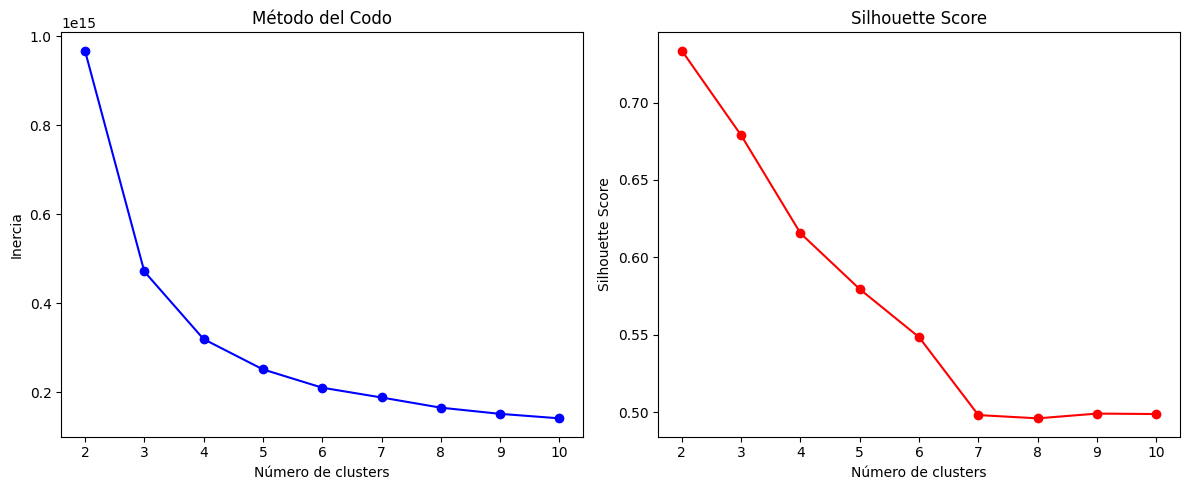

In [3]:
# 1. Cargamos el dataset caso 1
df = pd.read_csv('df_CC_NO_ED_Desbalanceado_Sin_Outlier_Sin_Variable_Objetivo.csv')

# 2 K-Means: Encontrar el número óptimo de clusters
inertia = []
silhouette = []
K = range(2, 11)

for k in K:
    kmeans = KMeans(n_clusters=k, random_state=42)
    labels = kmeans.fit_predict(df)
    inertia.append(kmeans.inertia_)
    silhouette.append(silhouette_score(df, labels))

# Graficar la curva del codo
plt.figure(figsize=(12,5))
plt.subplot(1,2,1)
plt.plot(K, inertia, 'bo-')
plt.xlabel('Número de clusters')
plt.ylabel('Inercia')
plt.title('Método del Codo')

# Graficar el silhouette score
plt.subplot(1,2,2)
plt.plot(K, silhouette, 'ro-')
plt.xlabel('Número de clusters')
plt.ylabel('Silhouette Score')
plt.title('Silhouette Score')
plt.tight_layout()
plt.show()

In [4]:
print("Inercia para cada K:", inertia)
print("Silhouette score para cada K:", silhouette)

# para k=4
print(inertia[2])  # Inercia para k=4
print(silhouette[2])  # Silhouette score para k=4

Inercia para cada K: [967702791476946.2, 471717601643677.75, 319839445949048.75, 251820461344766.38, 210696603034756.22, 188703990840901.97, 165787899234003.66, 151922591215180.56, 141830911685515.8]
Silhouette score para cada K: [np.float64(0.7334791179735828), np.float64(0.6787842162882639), np.float64(0.6155136874930948), np.float64(0.5793884728244023), np.float64(0.5483447776284268), np.float64(0.49801037343288884), np.float64(0.4959065490032849), np.float64(0.49897429828627693), np.float64(0.4986887421112457)]
319839445949048.75
0.6155136874930948


##### Justificación del valor de K

Dado que queremos 4 clausters nuestro debe ser K=4 y analizando las gráficas podemos validar que es una opción posible:

**Método del codo:** El "codo" más pronunciado está entre K=3 y K=4. Después de K=4, la reducción de inercia es menos significativa, lo que indica que agregar más clusters no mejora mucho la compactación.

**Silhouette Score:** El valor disminuye gradualmente, pero en K=4 aún es relativamente alto y la caída no es tan abrupta como después de K=4.
Conclusión:

Entonces se justifica el uso de K=4 tanto por el método del codo como por el silhouette score. Y es consistente con el objetivo de clasificar en 4 grupos.

In [5]:
# el mejor K 
optimal_k = 4

Distancia del primer punto a cada centroide:
[ 155258.41446815 2575160.82702723 1315845.89055134  478305.40367582]
    Centroide 0   Centroide 1   Centroide 2   Centroide 3
0  1.552584e+05  2.575161e+06  1.315846e+06  4.783054e+05
1  2.841655e+05  2.442757e+06  1.182466e+06  3.449224e+05
2  5.086860e+05  2.217570e+06  9.556351e+05  1.198737e+05
3  9.617049e+04  2.759710e+06  1.505446e+06  6.767780e+05
4  2.435435e+06  2.836481e+05  9.849230e+05  1.833033e+06


c:\Users\Cogito ergo sum\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\base.py:493: UserWarning: X does not have valid feature names, but PCA was fitted with feature names
  warnings.warn(
c:\Users\Cogito ergo sum\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\base.py:493: UserWarning: X does not have valid feature names, but PCA was fitted with feature names
  warnings.warn(


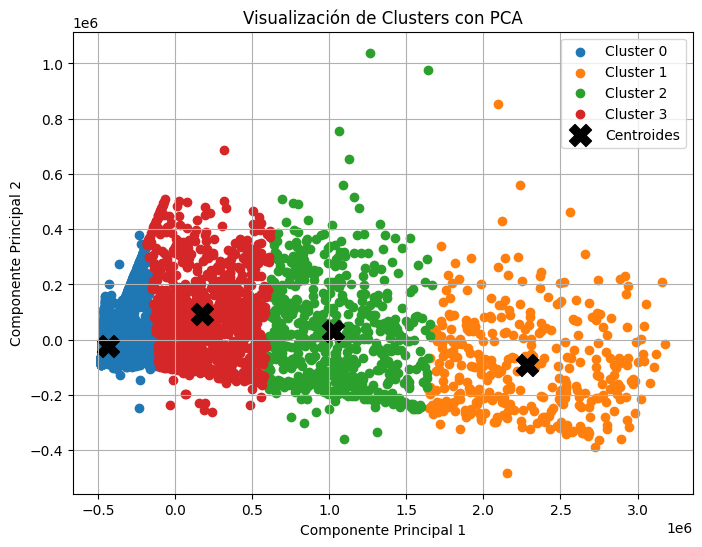

In [6]:
# 2. Entrenar KMeans con el número óptimo de clusters

kmeans = KMeans(n_clusters=optimal_k, random_state=42)
clusters = kmeans.fit_predict(df)

# 3. Calcular distancias a los centroides
distancias = cdist(df, kmeans.cluster_centers_, metric='euclidean')
print("Distancia del primer punto a cada centroide:")
print(distancias[0])

# Visualizar la matriz de distancias
dist_df = pd.DataFrame(distancias, columns=[f"Centroide {i}" for i in range(optimal_k)])
print(dist_df.head())

# 4. Visualización de clusters con PCA
pca = PCA(n_components=2)
X_pca = pca.fit_transform(df)

plt.figure(figsize=(8, 6))
for i in range(optimal_k):
    plt.scatter(X_pca[clusters == i, 0], X_pca[clusters == i, 1], label=f'Cluster {i}')

plt.scatter(pca.transform(kmeans.cluster_centers_)[:, 0],
            pca.transform(kmeans.cluster_centers_)[:, 1],
            s=250, c='black', marker='X', label='Centroides')
plt.title('Visualización de Clusters con PCA')
plt.xlabel('Componente Principal 1')
plt.ylabel('Componente Principal 2')
plt.legend()
plt.grid(True)
plt.show()

In [7]:
# Mostrar los valores de los centroides para cada variable
centroides = pd.DataFrame(kmeans.cluster_centers_, columns=df.columns)
print(centroides)

          amount  oldbalanceOrg  newbalanceOrig  oldbalanceDest  \
0   49340.471032   37053.935238    41245.318633    1.753107e+04   
1  192255.736189   22484.891032    21104.970258    1.851512e+06   
2  191563.966246   19751.935505    21753.665084    9.551365e+05   
3  183251.858328   24963.181436    19657.834103    3.659664e+05   

   newbalanceDest  type_CASH_IN  type_CASH_OUT  type_DEBIT  type_PAYMENT  \
0    3.760563e+04      0.102889       0.201376    0.004677  6.775791e-01   
1    2.036135e+06      0.091691       0.782235    0.008596  2.220446e-16   
2    1.145388e+06      0.107744       0.777778    0.011785 -2.775558e-16   
3    5.341789e+05      0.093333       0.805128    0.008205 -5.551115e-16   

   type_TRANSFER  
0       0.013480  
1       0.117479  
2       0.102694  
3       0.093333  


In [8]:
# # Agrega la columna de cluster al DataFrame
# df['cluster'] = clusters

# # Calcula el monto promedio y otras estadísticas por cluster
# resumen = df.groupby('cluster').agg({
#     'amount': ['mean', 'min', 'max', 'count'],
#     'oldbalanceOrg': 'mean',
#     'newbalanceOrig': 'mean'
# })
# print(resumen)

Casos de prueba

Transacción de prueba 1 pertenece al cluster: 0
Transacción de prueba 2 pertenece al cluster: 1
Transacción de prueba 3 pertenece al cluster: 3


c:\Users\Cogito ergo sum\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\base.py:493: UserWarning: X does not have valid feature names, but KMeans was fitted with feature names
  warnings.warn(
c:\Users\Cogito ergo sum\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\base.py:493: UserWarning: X does not have valid feature names, but PCA was fitted with feature names
  warnings.warn(
c:\Users\Cogito ergo sum\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\base.py:493: UserWarning: X does not have valid feature names, but PCA was fitted with feature names
  warnings.warn(
c:\Users\Cogito ergo sum\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\base.py:493: UserWarning: X does not have valid feature names, but PCA was fitted with feature names
  warnings.warn(


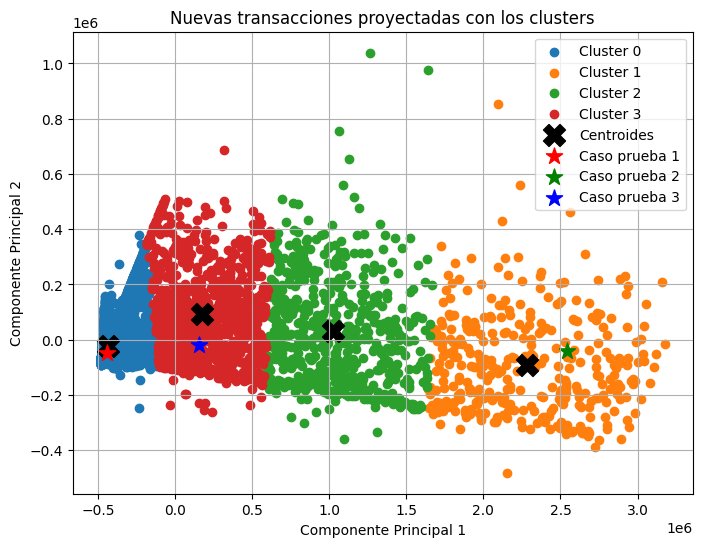

In [9]:
# Se ingresan: amount, oldbalanceOrg, newbalanceOrig, oldbalanceDest, newbalanceDest, type_CASH_IN, type_CASH_OUT, type_DEBIT, type_PAYMENT, type_TRANSFER

# Caso 1: (valores bajos-medios)
caso_1 = [10000, 5000, 0, 20000, 30000, 0, 0, 0, 1, 0]  # PAYMENT

# Caso 2: (valores muy altos)
caso_2 = [250000, 100000, 0, 2000000, 2250000, 0, 1, 0, 0, 0]  # CASH_OUT

# Caso 3: (valores intermedios)
caso_3 = [80000, 20000, 0, 400000, 480000, 0, 0, 0, 0, 1]  # TRANSFER

casos_prueba = np.array([caso_1, caso_2, caso_3])

# Predecir a qué cluster pertenece cada transacción
clusters_predichos = kmeans.predict(casos_prueba)
for i, cluster in enumerate(clusters_predichos):
    print(f"Transacción de prueba {i+1} pertenece al cluster: {cluster}")

# Proyectar las nuevas transacciones en el espacio PCA
casos_pca = pca.transform(casos_prueba)

# Graficar los clusters y las nuevas transacciones
plt.figure(figsize=(8, 6))
for i in range(optimal_k):
    plt.scatter(X_pca[clusters == i, 0], X_pca[clusters == i, 1], label=f'Cluster {i}')

plt.scatter(pca.transform(kmeans.cluster_centers_)[:, 0],
            pca.transform(kmeans.cluster_centers_)[:, 1],
            s=250, c='black', marker='X', label='Centroides')

colores = ['red', 'green', 'blue']
for i in range(3):
    plt.scatter(casos_pca[i, 0], casos_pca[i, 1], c=colores[i], s=150, marker='*', label=f'Caso prueba {i+1}')

plt.title('Nuevas transacciones proyectadas con los clusters')
plt.xlabel('Componente Principal 1')
plt.ylabel('Componente Principal 2')
plt.legend()
plt.grid(True)
plt.show()

##### Interpretación del caso de prueba 1: 

amount: 10000
→ El monto de la transacción es 10,000 unidades monetarias (valor bajo-medio).

oldbalanceOrg: 5000
→ El saldo anterior del origen (quien envía el dinero) es 5,000.

newbalanceOrig: 0
→ El saldo nuevo del origen después de la transacción es 0 (se quedó sin saldo).

oldbalanceDest: 20000
→ El saldo anterior del destino (quien recibe el dinero) es 20,000.

newbalanceDest: 30000
→ El saldo nuevo del destino después de la transacción es 30,000.

type_CASH_IN: 0
→ No es una transacción de tipo CASH_IN.

type_CASH_OUT: 0
→ No es una transacción de tipo CASH_OUT.

type_DEBIT: 0
→ No es una transacción de tipo DEBIT.

type_PAYMENT: 1
→ Es una transacción de tipo PAYMENT (pago).

type_TRANSFER: 0
→ No es una transacción de tipo TRANSFER.

#### DBSCAN

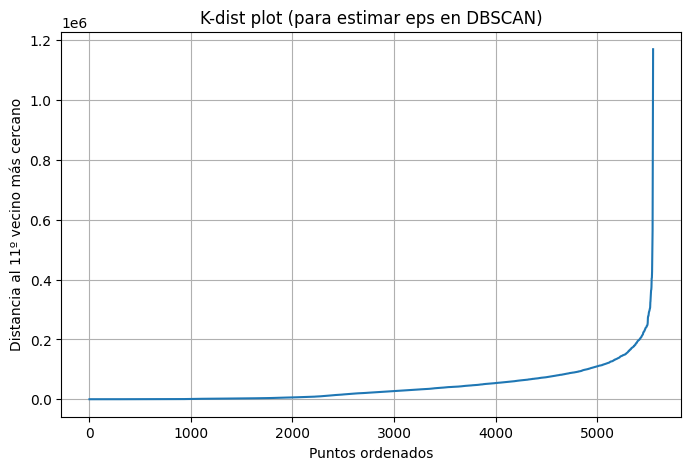

In [10]:
from sklearn.cluster import DBSCAN
from sklearn.neighbors import NearestNeighbors
from sklearn.decomposition import PCA
import numpy as np
import matplotlib.pyplot as plt

# Usamos los datos originales (sin escalar)
X = df.values

# 1. Gráfico K-dist para estimar eps
min_samples = 11  # MinPts = número de features + 1 = 10 + 1 = 11
neighbors = NearestNeighbors(n_neighbors=min_samples)
neighbors_fit = neighbors.fit(X)
distances, indices = neighbors_fit.kneighbors(X)
distances = np.sort(distances[:, min_samples-1])  # Tomamos la 11va distancia más cercana

plt.figure(figsize=(8, 5))
plt.plot(distances)
plt.title('K-dist plot (para estimar eps en DBSCAN)')
plt.xlabel('Puntos ordenados')
plt.ylabel(f'Distancia al {min_samples}º vecino más cercano')
plt.grid(True)
plt.show()


DBSCAN detectó 2 clusters


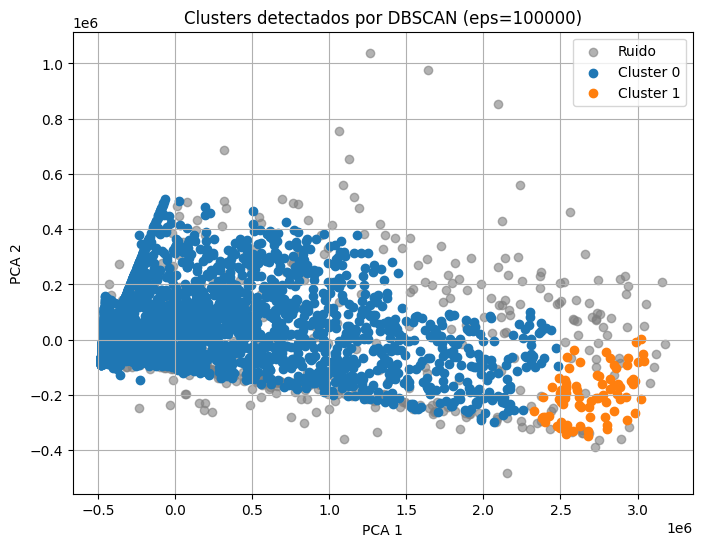

In [11]:

# 2. Se selecciona eps visualmente
eps_val =  100000 

# 3. Entrenamiento DBSCAN
dbscan = DBSCAN(eps=eps_val, min_samples=min_samples)
db_labels = dbscan.fit_predict(X)

# 4. Número de clusters detectados (sin contar ruido -1)
n_clusters = len(set(db_labels)) - (1 if -1 in db_labels else 0)
print(f"DBSCAN detectó {n_clusters} clusters")

# 5. Visualización con PCA
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X)

plt.figure(figsize=(8, 6))
for label in np.unique(db_labels):
    if label == -1:
        plt.scatter(X_pca[db_labels == label, 0], X_pca[db_labels == label, 1],
                    c='gray', label='Ruido', alpha=0.6)
    else:
        plt.scatter(X_pca[db_labels == label, 0], X_pca[db_labels == label, 1],
                    label=f'Cluster {label}')
plt.title(f'Clusters detectados por DBSCAN (eps={eps_val})')
plt.xlabel('PCA 1')
plt.ylabel('PCA 2')
plt.legend()
plt.grid(True)
plt.show()

Transacción de prueba 1 pertenecería al Cluster 0
Transacción de prueba 2 es considerada ruido (no pertenece a ningún cluster).
Transacción de prueba 3 pertenecería al Cluster 0


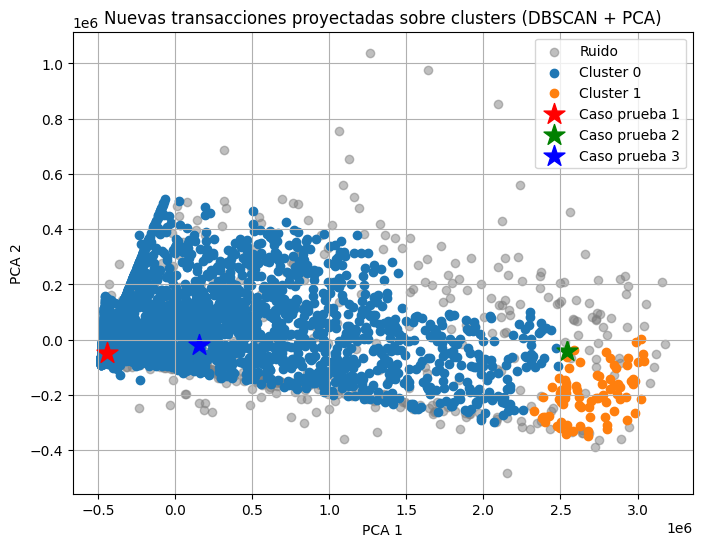

Silhouette score para DBSCAN: 0.7417909864406107


In [12]:

# 6. Casos de prueba (3 transacciones nuevas)
casos_prueba = np.array([
    [10000, 5000, 0, 20000, 30000, 0, 0, 0, 1, 0],      # Caso 1: PAYMENT, valores bajos-medios
    [250000, 100000, 0, 2000000, 2250000, 0, 1, 0, 0, 0], # Caso 2: CASH_OUT, valores muy altos
    [80000, 20000, 0, 400000, 480000, 0, 0, 0, 0, 1]      # Caso 3: TRANSFER, valores intermedios
])

# Predecir a qué cluster (o ruido) pertenece cada transacción de prueba
X_ext = np.vstack([X, casos_prueba])
db_labels_ext = dbscan.fit_predict(X_ext)
casos_predichos = db_labels_ext[-3:]

for i, cluster in enumerate(casos_predichos):
    if cluster == -1:
        print(f"Transacción de prueba {i+1} es considerada ruido (no pertenece a ningún cluster).")
    else:
        print(f"Transacción de prueba {i+1} pertenecería al Cluster {cluster}")

# Proyectar las nuevas transacciones en el espacio PCA
casos_pca = pca.transform(casos_prueba)

plt.figure(figsize=(8, 6))
for label in np.unique(db_labels):
    if label == -1:
        plt.scatter(X_pca[db_labels == label, 0], X_pca[db_labels == label, 1],
                    c='gray', label='Ruido', alpha=0.5)
    else:
        plt.scatter(X_pca[db_labels == label, 0], X_pca[db_labels == label, 1],
                    label=f'Cluster {label}')

colores = ['red', 'green', 'blue']
for i in range(3):
    plt.scatter(casos_pca[i, 0], casos_pca[i, 1], c=colores[i], s=250, marker='*', label=f'Caso prueba {i+1}')

plt.title('Nuevas transacciones proyectadas sobre clusters (DBSCAN + PCA)')
plt.xlabel('PCA 1')
plt.ylabel('PCA 2')
plt.legend()
plt.grid(True)
plt.show()

# 7. Silhouette score para DBSCAN
from sklearn.metrics import silhouette_score
if len(set(db_labels)) - (1 if -1 in db_labels else 0) > 1:
    mask = db_labels != -1
    sil_score = silhouette_score(X[mask], db_labels[mask])
    print(f"Silhouette score para DBSCAN: {sil_score}")
else:
    print("No se puede calcular silhouette score: menos de 2 clusters detectados.")

### Caso 2: CC(SI), ED(NO), Outliers (NO), Balanceo(SI)


#### K-MEANS

Determinamos el número óptimo de clusters con el método del codo y silhouette

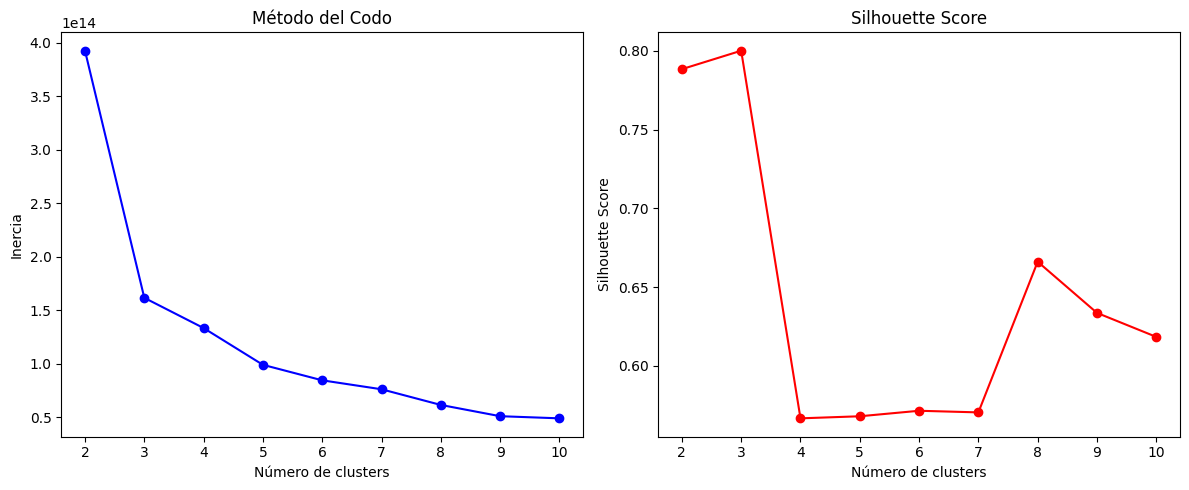

In [13]:
# 1. Cargamos el dataset caso 1
df = pd.read_csv('df_CC_NO_ED_Balanceado_Sin_Outliers_Sin_Variable_Objetivo.csv')

# 2 K-Means: Encontrar el número óptimo de clusters
inertia = []
silhouette = []
K = range(2, 11)

for k in K:
    kmeans = KMeans(n_clusters=k, random_state=42)
    labels = kmeans.fit_predict(df)
    inertia.append(kmeans.inertia_)
    silhouette.append(silhouette_score(df, labels))

# Graficar la curva del codo
plt.figure(figsize=(12,5))
plt.subplot(1,2,1)
plt.plot(K, inertia, 'bo-')
plt.xlabel('Número de clusters')
plt.ylabel('Inercia')
plt.title('Método del Codo')

# Graficar el silhouette score
plt.subplot(1,2,2)
plt.plot(K, silhouette, 'ro-')
plt.xlabel('Número de clusters')
plt.ylabel('Silhouette Score')
plt.title('Silhouette Score')
plt.tight_layout()
plt.show()

In [14]:
print("Inercia para cada K:", inertia)
print("Silhouette score para cada K:", silhouette)

# para k=3
print(inertia[1])  # Inercia para k=3
print(silhouette[1])  # Silhouette score para k=3

Inercia para cada K: [392492357563668.56, 161479584765451.56, 133209278408174.98, 98836980714536.64, 84341235660159.66, 75981684807001.22, 61326914764348.66, 50806719467315.81, 48798441224751.22]
Silhouette score para cada K: [np.float64(0.7884265369446287), np.float64(0.8001333311723312), np.float64(0.566771970033362), np.float64(0.5680852901267961), np.float64(0.571580481270908), np.float64(0.570548593050987), np.float64(0.666195310278487), np.float64(0.6337070647447267), np.float64(0.6184781523590033)]
161479584765451.56
0.8001333311723312


##### Justificación del valor de K

El valor óptimo de k es 3, ya que en el método del codo se observa un quiebre claro en ese punto, lo que indica que aumentar el número de clústers después de 3 reduce la inercia de forma menos significativa. Además, el Silhouette Score alcanza su valor máximo en k = 3, lo que indica una excelente cohesión y separación entre clústers,

In [15]:
# el mejor K 
optimal_k = 3

Distancia del primer punto a cada centroide:
[  83573.06959944  797425.99340833 2284533.30825288]
     Centroide 0    Centroide 1   Centroide 2
0   83573.069599  797425.993408  2.284533e+06
1  120779.044495  891706.166514  2.376130e+06
2  142350.135937  909322.431834  2.378285e+06
3   83435.072227  797434.402377  2.284529e+06
4  118708.578811  904332.638454  2.376750e+06


c:\Users\Cogito ergo sum\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\base.py:493: UserWarning: X does not have valid feature names, but PCA was fitted with feature names
  warnings.warn(
c:\Users\Cogito ergo sum\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\base.py:493: UserWarning: X does not have valid feature names, but PCA was fitted with feature names
  warnings.warn(


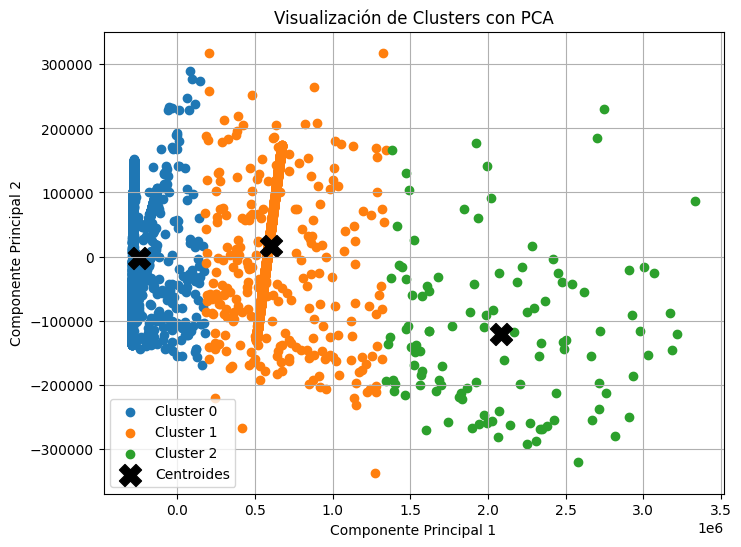

In [16]:
# 2. Entrenar KMeans con el número óptimo de clusters

kmeans = KMeans(n_clusters=optimal_k, random_state=42)
clusters = kmeans.fit_predict(df)

# 3. Calcular distancias a los centroides
distancias = cdist(df, kmeans.cluster_centers_, metric='euclidean')
print("Distancia del primer punto a cada centroide:")
print(distancias[0])

# Visualizar la matriz de distancias
dist_df = pd.DataFrame(distancias, columns=[f"Centroide {i}" for i in range(optimal_k)])
print(dist_df.head())

# 4. Visualización de clusters con PCA
pca = PCA(n_components=2)
X_pca = pca.fit_transform(df)

plt.figure(figsize=(8, 6))
for i in range(optimal_k):
    plt.scatter(X_pca[clusters == i, 0], X_pca[clusters == i, 1], label=f'Cluster {i}')

plt.scatter(pca.transform(kmeans.cluster_centers_)[:, 0],
            pca.transform(kmeans.cluster_centers_)[:, 1],
            s=250, c='black', marker='X', label='Centroides')
plt.title('Visualización de Clusters con PCA')
plt.xlabel('Componente Principal 1')
plt.ylabel('Componente Principal 2')
plt.legend()
plt.grid(True)
plt.show()

In [17]:
# Mostrar los valores de los centroides para cada variable
centroides = pd.DataFrame(kmeans.cluster_centers_, columns=df.columns)
print(centroides)

          amount  oldbalanceOrg  newbalanceOrig  oldbalanceDest  \
0  100007.064601   96548.162828     8821.883084    5.301143e+03   
1  149180.116817  122105.822383     3893.661747    5.517990e+05   
2  188432.589912   19224.999115    22175.491239    1.588914e+06   

   newbalanceDest  type_CASH_IN  type_CASH_OUT  type_DEBIT  type_PAYMENT  \
0    4.697596e+04      0.020725       0.314035    0.000451  1.216490e-01   
1    6.977973e+05      0.019337       0.964088    0.002072  9.714451e-17   
2    1.759531e+06      0.106195       0.778761    0.008850 -1.387779e-17   

   type_TRANSFER  
0       0.543140  
1       0.014503  
2       0.106195  


In [18]:
# # Agrega la columna de cluster al DataFrame
# df['cluster'] = clusters

# # Calcula el monto promedio y otras estadísticas por cluster
# resumen = df.groupby('cluster').agg({
#     'amount': ['mean', 'min', 'max', 'count'],
#     'oldbalanceOrg': 'mean',
#     'newbalanceOrig': 'mean'
# })
# print(resumen)

Casos de prueba

Transacción de prueba 1 pertenece al cluster: 0
Transacción de prueba 2 pertenece al cluster: 2
Transacción de prueba 3 pertenece al cluster: 1


c:\Users\Cogito ergo sum\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\base.py:493: UserWarning: X does not have valid feature names, but KMeans was fitted with feature names
  warnings.warn(
c:\Users\Cogito ergo sum\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\base.py:493: UserWarning: X does not have valid feature names, but PCA was fitted with feature names
  warnings.warn(
c:\Users\Cogito ergo sum\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\base.py:493: UserWarning: X does not have valid feature names, but PCA was fitted with feature names
  warnings.warn(
c:\Users\Cogito ergo sum\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\base.py:493: UserWarning: X does not have valid feature names, but PCA was fitted with feature names
  warnings.warn(


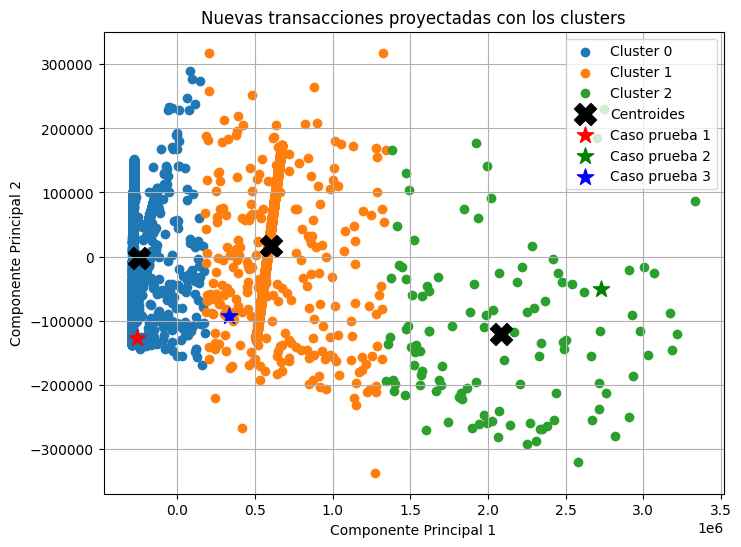

In [19]:
# Se ingresan: amount, oldbalanceOrg, newbalanceOrig, oldbalanceDest, newbalanceDest, type_CASH_IN, type_CASH_OUT, type_DEBIT, type_PAYMENT, type_TRANSFER

# Caso 1: (valores bajos-medios)
caso_1 = [10000, 5000, 0, 20000, 30000, 0, 0, 0, 1, 0]  # PAYMENT

# Caso 2: (valores muy altos)
caso_2 = [250000, 100000, 0, 2000000, 2250000, 0, 1, 0, 0, 0]  # CASH_OUT

# Caso 3: (valores intermedios)
caso_3 = [80000, 20000, 0, 400000, 480000, 0, 0, 0, 0, 1]  # TRANSFER

casos_prueba = np.array([caso_1, caso_2, caso_3])

# Predecir a qué cluster pertenece cada transacción
clusters_predichos = kmeans.predict(casos_prueba)
for i, cluster in enumerate(clusters_predichos):
    print(f"Transacción de prueba {i+1} pertenece al cluster: {cluster}")

# Proyectar las nuevas transacciones en el espacio PCA
casos_pca = pca.transform(casos_prueba)

# Graficar los clusters y las nuevas transacciones
plt.figure(figsize=(8, 6))
for i in range(optimal_k):
    plt.scatter(X_pca[clusters == i, 0], X_pca[clusters == i, 1], label=f'Cluster {i}')

plt.scatter(pca.transform(kmeans.cluster_centers_)[:, 0],
            pca.transform(kmeans.cluster_centers_)[:, 1],
            s=250, c='black', marker='X', label='Centroides')

colores = ['red', 'green', 'blue']
for i in range(3):
    plt.scatter(casos_pca[i, 0], casos_pca[i, 1], c=colores[i], s=150, marker='*', label=f'Caso prueba {i+1}')

plt.title('Nuevas transacciones proyectadas con los clusters')
plt.xlabel('Componente Principal 1')
plt.ylabel('Componente Principal 2')
plt.legend()
plt.grid(True)
plt.show()

##### Interpretación del caso de prueba 1: 

amount: 10000
→ El monto de la transacción es 10,000 unidades monetarias (valor bajo-medio).

oldbalanceOrg: 5000
→ El saldo anterior del origen (quien envía el dinero) es 5,000.

newbalanceOrig: 0
→ El saldo nuevo del origen después de la transacción es 0 (se quedó sin saldo).

oldbalanceDest: 20000
→ El saldo anterior del destino (quien recibe el dinero) es 20,000.

newbalanceDest: 30000
→ El saldo nuevo del destino después de la transacción es 30,000.

type_CASH_IN: 0
→ No es una transacción de tipo CASH_IN.

type_CASH_OUT: 0
→ No es una transacción de tipo CASH_OUT.

type_DEBIT: 0
→ No es una transacción de tipo DEBIT.

type_PAYMENT: 1
→ Es una transacción de tipo PAYMENT (pago).

type_TRANSFER: 0
→ No es una transacción de tipo TRANSFER.

#### DBSCAN

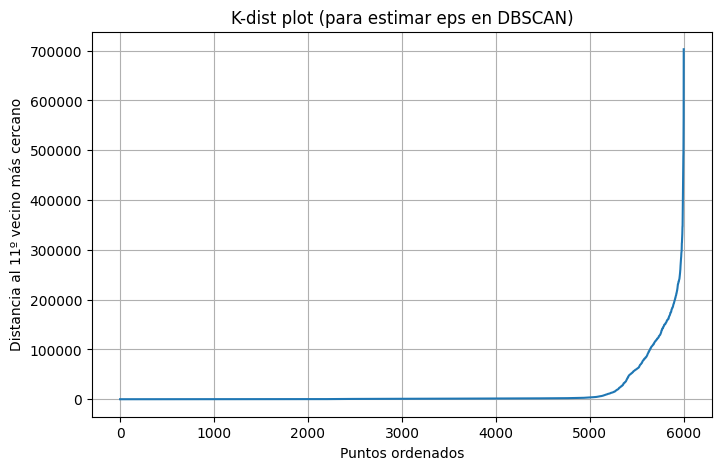

In [20]:
from sklearn.cluster import DBSCAN
from sklearn.neighbors import NearestNeighbors
from sklearn.decomposition import PCA
import numpy as np
import matplotlib.pyplot as plt

# Usamos los datos originales (sin escalar)
X = df.values

# 1. Gráfico K-dist para estimar eps
min_samples = 11  # MinPts = número de features + 1 = 10 + 1 = 11
neighbors = NearestNeighbors(n_neighbors=min_samples)
neighbors_fit = neighbors.fit(X)
distances, indices = neighbors_fit.kneighbors(X)
distances = np.sort(distances[:, min_samples-1])  # Tomamos la 11va distancia más cercana

plt.figure(figsize=(8, 5))
plt.plot(distances)
plt.title('K-dist plot (para estimar eps en DBSCAN)')
plt.xlabel('Puntos ordenados')
plt.ylabel(f'Distancia al {min_samples}º vecino más cercano')
plt.grid(True)
plt.show()


DBSCAN detectó 2 clusters


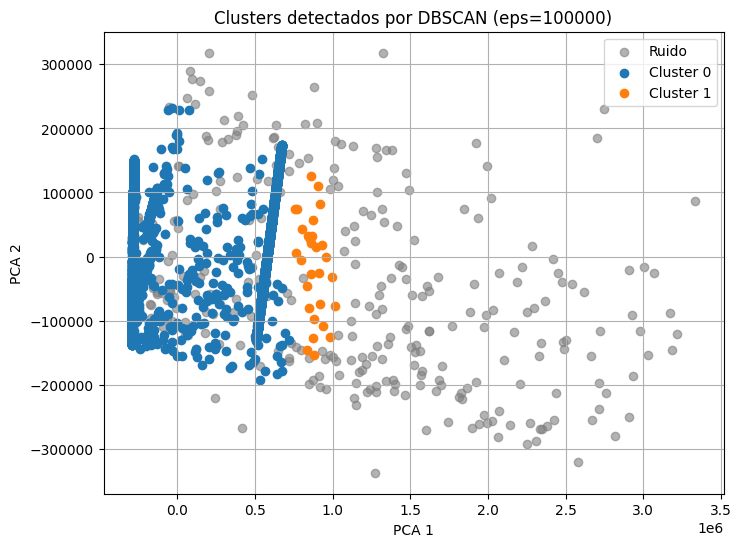

In [21]:

# 2. Se selecciona eps visualmente
eps_val =  100000 # Usando el valor sugerido (0.2*10^6)

# 3. Entrenamiento DBSCAN
dbscan = DBSCAN(eps=eps_val, min_samples=min_samples)
db_labels = dbscan.fit_predict(X)

# 4. Número de clusters detectados (sin contar ruido -1)
n_clusters = len(set(db_labels)) - (1 if -1 in db_labels else 0)
print(f"DBSCAN detectó {n_clusters} clusters")

# 5. Visualización con PCA
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X)

plt.figure(figsize=(8, 6))
for label in np.unique(db_labels):
    if label == -1:
        plt.scatter(X_pca[db_labels == label, 0], X_pca[db_labels == label, 1],
                    c='gray', label='Ruido', alpha=0.6)
    else:
        plt.scatter(X_pca[db_labels == label, 0], X_pca[db_labels == label, 1],
                    label=f'Cluster {label}')
plt.title(f'Clusters detectados por DBSCAN (eps={eps_val})')
plt.xlabel('PCA 1')
plt.ylabel('PCA 2')
plt.legend()
plt.grid(True)
plt.show()

Transacción de prueba 1 pertenecería al Cluster 0
Transacción de prueba 2 es considerada ruido (no pertenece a ningún cluster).
Transacción de prueba 3 pertenecería al Cluster 0


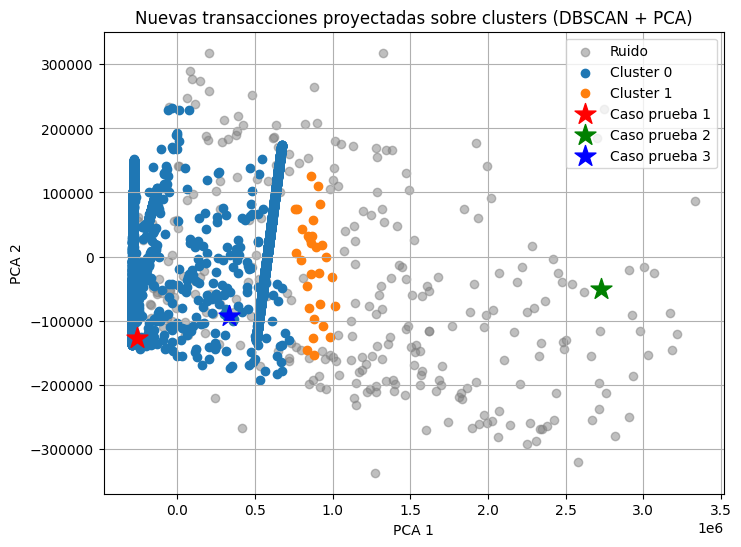

Silhouette score para DBSCAN: 0.46373180418046833


In [22]:

# 6. Casos de prueba (3 transacciones nuevas)
casos_prueba = np.array([
    [10000, 5000, 0, 20000, 30000, 0, 0, 0, 1, 0],      # Caso 1: PAYMENT, valores bajos-medios
    [250000, 100000, 0, 2000000, 2250000, 0, 1, 0, 0, 0], # Caso 2: CASH_OUT, valores muy altos
    [80000, 20000, 0, 400000, 480000, 0, 0, 0, 0, 1]      # Caso 3: TRANSFER, valores intermedios
])

# Predecir a qué cluster (o ruido) pertenece cada transacción de prueba
X_ext = np.vstack([X, casos_prueba])
db_labels_ext = dbscan.fit_predict(X_ext)
casos_predichos = db_labels_ext[-3:]

for i, cluster in enumerate(casos_predichos):
    if cluster == -1:
        print(f"Transacción de prueba {i+1} es considerada ruido (no pertenece a ningún cluster).")
    else:
        print(f"Transacción de prueba {i+1} pertenecería al Cluster {cluster}")

# Proyectar las nuevas transacciones en el espacio PCA
casos_pca = pca.transform(casos_prueba)

plt.figure(figsize=(8, 6))
for label in np.unique(db_labels):
    if label == -1:
        plt.scatter(X_pca[db_labels == label, 0], X_pca[db_labels == label, 1],
                    c='gray', label='Ruido', alpha=0.5)
    else:
        plt.scatter(X_pca[db_labels == label, 0], X_pca[db_labels == label, 1],
                    label=f'Cluster {label}')

colores = ['red', 'green', 'blue']
for i in range(3):
    plt.scatter(casos_pca[i, 0], casos_pca[i, 1], c=colores[i], s=250, marker='*', label=f'Caso prueba {i+1}')

plt.title('Nuevas transacciones proyectadas sobre clusters (DBSCAN + PCA)')
plt.xlabel('PCA 1')
plt.ylabel('PCA 2')
plt.legend()
plt.grid(True)
plt.show()

# 7. Silhouette score para DBSCAN
from sklearn.metrics import silhouette_score
if len(set(db_labels)) - (1 if -1 in db_labels else 0) > 1:
    mask = db_labels != -1
    sil_score = silhouette_score(X[mask], db_labels[mask])
    print(f"Silhouette score para DBSCAN: {sil_score}")
else:
    print("No se puede calcular silhouette score: menos de 2 clusters detectados.")

### Caso 3: CC(SI), ED(NO), Outliers (SI), Balanceo(NO)


#### K-MEANS

Determinamos el número óptimo de clusters con el método del codo y silhouette

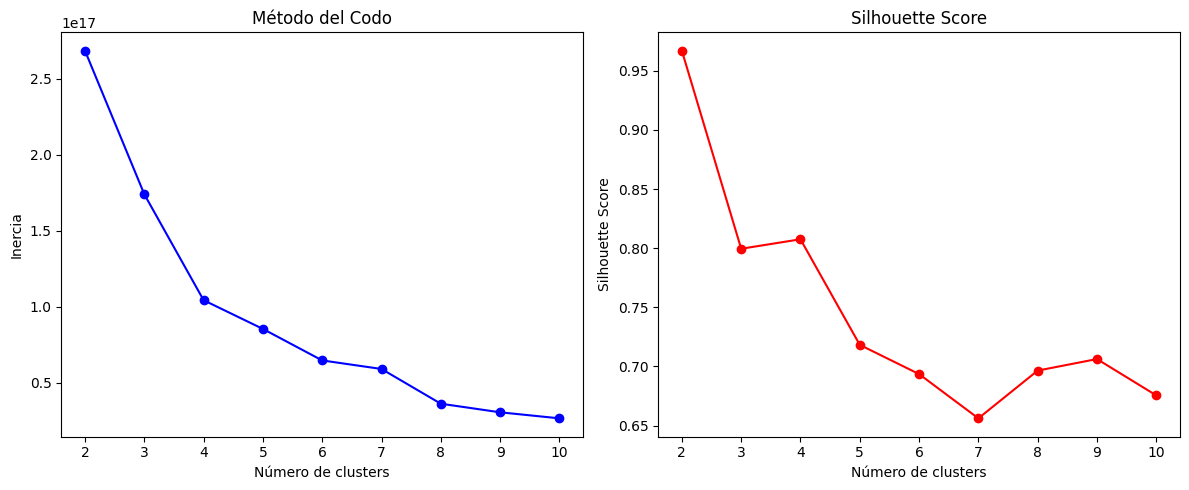

In [23]:
# 1. Cargamos el dataset caso 1
df = pd.read_csv('df_CC_NO_ED_Desbalanceado_Con_Outliers_Sin_Variable_Objetivo.csv')

# 2 K-Means: Encontrar el número óptimo de clusters
inertia = []
silhouette = []
K = range(2, 11)

for k in K:
    kmeans = KMeans(n_clusters=k, random_state=42)
    labels = kmeans.fit_predict(df)
    inertia.append(kmeans.inertia_)
    silhouette.append(silhouette_score(df, labels))

# Graficar la curva del codo
plt.figure(figsize=(12,5))
plt.subplot(1,2,1)
plt.plot(K, inertia, 'bo-')
plt.xlabel('Número de clusters')
plt.ylabel('Inercia')
plt.title('Método del Codo')

# Graficar el silhouette score
plt.subplot(1,2,2)
plt.plot(K, silhouette, 'ro-')
plt.xlabel('Número de clusters')
plt.ylabel('Silhouette Score')
plt.title('Silhouette Score')
plt.tight_layout()
plt.show()

In [24]:
print("Inercia para cada K:", inertia)
print("Silhouette score para cada K:", silhouette)

# para k=4
print(inertia[2])  # Inercia para k=3
print(silhouette[2])  # Silhouette score para k=3

Inercia para cada K: [2.6829094110111766e+17, 1.7393779004145827e+17, 1.042704481093908e+17, 8.538758758656181e+16, 6.467710092354631e+16, 5.905864076564262e+16, 3.622816372526779e+16, 3.0576438666321176e+16, 2.6606636816643196e+16]
Silhouette score para cada K: [np.float64(0.9670276332404425), np.float64(0.7995599394231218), np.float64(0.8075802827226156), np.float64(0.7182923605952037), np.float64(0.6935844642729976), np.float64(0.6561517678113229), np.float64(0.6965328756739603), np.float64(0.7062920567356248), np.float64(0.6755580007614831)]
1.042704481093908e+17
0.8075802827226156


In [25]:
# el mejor K 
optimal_k = 4

Distancia del primer punto a cada centroide:
[3.99367692e+06 1.35912543e+08 1.17825431e+07 1.53219402e+07]
    Centroide 0   Centroide 1   Centroide 2   Centroide 3
0  3.993677e+06  1.359125e+08  1.178254e+07  1.532194e+07
1  8.200606e+05  1.358793e+08  1.605089e+07  1.494190e+07
2  1.227530e+07  1.228932e+08  1.939227e+07  2.096839e+06
3  7.041515e+05  1.357467e+08  1.603558e+07  1.480960e+07
4  5.143951e+05  1.355208e+08  1.599311e+07  1.458342e+07


c:\Users\Cogito ergo sum\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\base.py:493: UserWarning: X does not have valid feature names, but PCA was fitted with feature names
  warnings.warn(
c:\Users\Cogito ergo sum\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\base.py:493: UserWarning: X does not have valid feature names, but PCA was fitted with feature names
  warnings.warn(


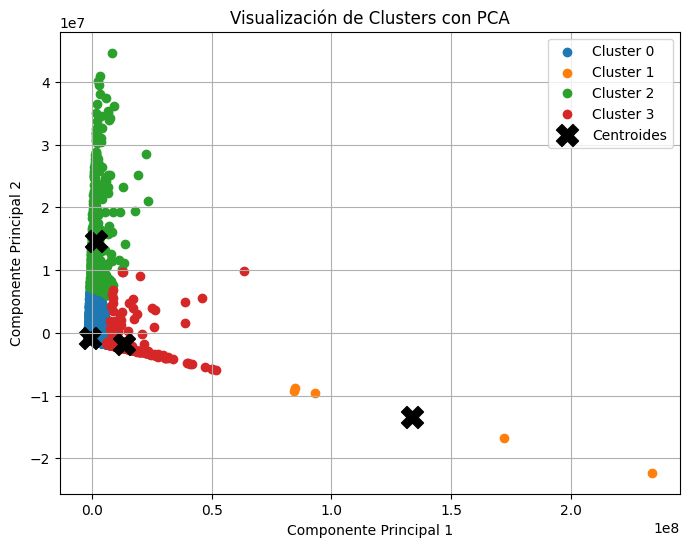

In [26]:
# 2. Entrenar KMeans con el número óptimo de clusters

kmeans = KMeans(n_clusters=optimal_k, random_state=42)
clusters = kmeans.fit_predict(df)

# 3. Calcular distancias a los centroides
distancias = cdist(df, kmeans.cluster_centers_, metric='euclidean')
print("Distancia del primer punto a cada centroide:")
print(distancias[0])

# Visualizar la matriz de distancias
dist_df = pd.DataFrame(distancias, columns=[f"Centroide {i}" for i in range(optimal_k)])
print(dist_df.head())

# 4. Visualización de clusters con PCA
pca = PCA(n_components=2)
X_pca = pca.fit_transform(df)

plt.figure(figsize=(8, 6))
for i in range(optimal_k):
    plt.scatter(X_pca[clusters == i, 0], X_pca[clusters == i, 1], label=f'Cluster {i}')

plt.scatter(pca.transform(kmeans.cluster_centers_)[:, 0],
            pca.transform(kmeans.cluster_centers_)[:, 1],
            s=250, c='black', marker='X', label='Centroides')
plt.title('Visualización de Clusters con PCA')
plt.xlabel('Componente Principal 1')
plt.ylabel('Componente Principal 2')
plt.legend()
plt.grid(True)
plt.show()

In [27]:
# Mostrar los valores de los centroides para cada variable
centroides = pd.DataFrame(kmeans.cluster_centers_, columns=df.columns)
print(centroides)

         amount  oldbalanceOrg  newbalanceOrig  oldbalanceDest  \
0  1.518199e+05   2.570927e+05    2.711320e+05    5.878274e+05   
1  6.854068e+06   2.152600e+03   -1.164153e-10    9.260033e+07   
2  1.770818e+05   1.120058e+07    1.133015e+07    1.569358e+06   
3  7.446591e+05   4.808459e+05    5.020525e+05    1.029703e+07   

   newbalanceDest  type_CASH_IN  type_CASH_OUT    type_DEBIT  type_PAYMENT  \
0    6.895148e+05      0.178502   3.755181e-01  6.079027e-03  3.675048e-01   
1    9.945440e+07      0.000000   4.000000e-01  0.000000e+00  0.000000e+00   
2    1.429411e+06      0.997625   1.665335e-16 -1.734723e-18  2.220446e-16   
3    1.103109e+07      0.219373   4.501425e-01  1.139601e-02  1.665335e-16   

   type_TRANSFER  
0       0.072396  
1       0.600000  
2       0.002375  
3       0.319088  


In [28]:
# # Agrega la columna de cluster al DataFrame
# df['cluster'] = clusters

# # Calcula el monto promedio y otras estadísticas por cluster
# resumen = df.groupby('cluster').agg({
#     'amount': ['mean', 'min', 'max', 'count'],
#     'oldbalanceOrg': 'mean',
#     'newbalanceOrig': 'mean'
# })
# print(resumen)

Casos de prueba

Transacción de prueba 1 pertenece al cluster: 0
Transacción de prueba 2 pertenece al cluster: 0
Transacción de prueba 3 pertenece al cluster: 0


c:\Users\Cogito ergo sum\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\base.py:493: UserWarning: X does not have valid feature names, but KMeans was fitted with feature names
  warnings.warn(
c:\Users\Cogito ergo sum\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\base.py:493: UserWarning: X does not have valid feature names, but PCA was fitted with feature names
  warnings.warn(
c:\Users\Cogito ergo sum\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\base.py:493: UserWarning: X does not have valid feature names, but PCA was fitted with feature names
  warnings.warn(
c:\Users\Cogito ergo sum\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\base.py:493: UserWarning: X does not have valid feature names, but PCA was fitted with feature names
  warnings.warn(


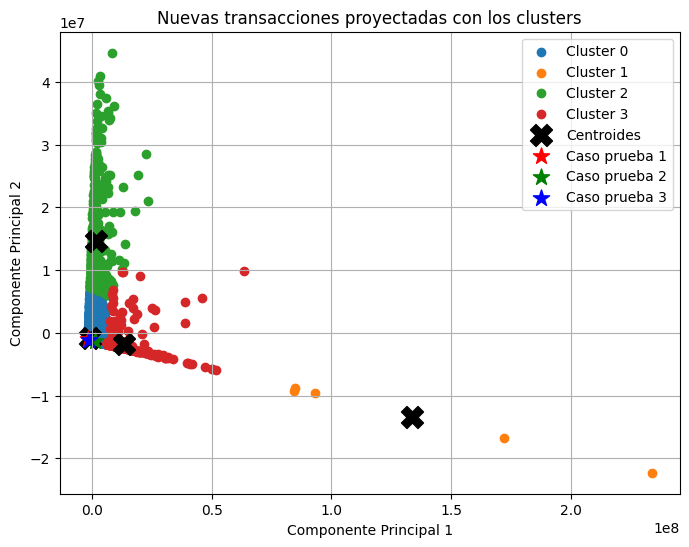

In [29]:
# Se ingresan: amount, oldbalanceOrg, newbalanceOrig, oldbalanceDest, newbalanceDest, type_CASH_IN, type_CASH_OUT, type_DEBIT, type_PAYMENT, type_TRANSFER

# Caso 1: (valores bajos-medios)
caso_1 = [10000, 5000, 0, 20000, 30000, 0, 0, 0, 1, 0]  # PAYMENT

# Caso 2: (valores muy altos)
caso_2 = [250000, 100000, 0, 2000000, 2250000, 0, 1, 0, 0, 0]  # CASH_OUT

# Caso 3: (valores intermedios)
caso_3 = [80000, 20000, 0, 400000, 480000, 0, 0, 0, 0, 1]  # TRANSFER

casos_prueba = np.array([caso_1, caso_2, caso_3])

# Predecir a qué cluster pertenece cada transacción
clusters_predichos = kmeans.predict(casos_prueba)
for i, cluster in enumerate(clusters_predichos):
    print(f"Transacción de prueba {i+1} pertenece al cluster: {cluster}")

# Proyectar las nuevas transacciones en el espacio PCA
casos_pca = pca.transform(casos_prueba)

# Graficar los clusters y las nuevas transacciones
plt.figure(figsize=(8, 6))
for i in range(optimal_k):
    plt.scatter(X_pca[clusters == i, 0], X_pca[clusters == i, 1], label=f'Cluster {i}')

plt.scatter(pca.transform(kmeans.cluster_centers_)[:, 0],
            pca.transform(kmeans.cluster_centers_)[:, 1],
            s=250, c='black', marker='X', label='Centroides')

colores = ['red', 'green', 'blue']
for i in range(3):
    plt.scatter(casos_pca[i, 0], casos_pca[i, 1], c=colores[i], s=150, marker='*', label=f'Caso prueba {i+1}')

plt.title('Nuevas transacciones proyectadas con los clusters')
plt.xlabel('Componente Principal 1')
plt.ylabel('Componente Principal 2')
plt.legend()
plt.grid(True)
plt.show()

##### Interpretación del caso de prueba 1: 

amount: 10000
→ El monto de la transacción es 10,000 unidades monetarias (valor bajo-medio).

oldbalanceOrg: 5000
→ El saldo anterior del origen (quien envía el dinero) es 5,000.

newbalanceOrig: 0
→ El saldo nuevo del origen después de la transacción es 0 (se quedó sin saldo).

oldbalanceDest: 20000
→ El saldo anterior del destino (quien recibe el dinero) es 20,000.

newbalanceDest: 30000
→ El saldo nuevo del destino después de la transacción es 30,000.

type_CASH_IN: 0
→ No es una transacción de tipo CASH_IN.

type_CASH_OUT: 0
→ No es una transacción de tipo CASH_OUT.

type_DEBIT: 0
→ No es una transacción de tipo DEBIT.

type_PAYMENT: 1
→ Es una transacción de tipo PAYMENT (pago).

type_TRANSFER: 0
→ No es una transacción de tipo TRANSFER.

#### DBSCAN

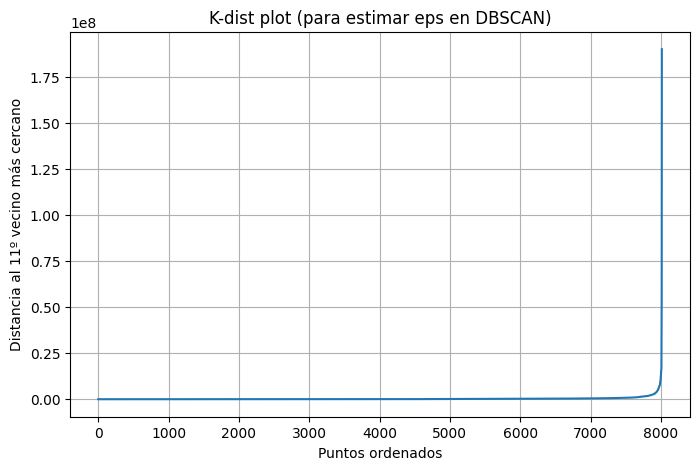

In [30]:
from sklearn.cluster import DBSCAN
from sklearn.neighbors import NearestNeighbors
from sklearn.decomposition import PCA
import numpy as np
import matplotlib.pyplot as plt

# Usamos los datos originales (sin escalar)
X = df.values

# 1. Gráfico K-dist para estimar eps
min_samples = 11  # MinPts = número de features + 1 = 10 + 1 = 11
neighbors = NearestNeighbors(n_neighbors=min_samples)
neighbors_fit = neighbors.fit(X)
distances, indices = neighbors_fit.kneighbors(X)
distances = np.sort(distances[:, min_samples-1])  # Tomamos la 11va distancia más cercana

plt.figure(figsize=(8, 5))
plt.plot(distances)
plt.title('K-dist plot (para estimar eps en DBSCAN)')
plt.xlabel('Puntos ordenados')
plt.ylabel(f'Distancia al {min_samples}º vecino más cercano')
plt.grid(True)
plt.show()


DBSCAN detectó 3 clusters


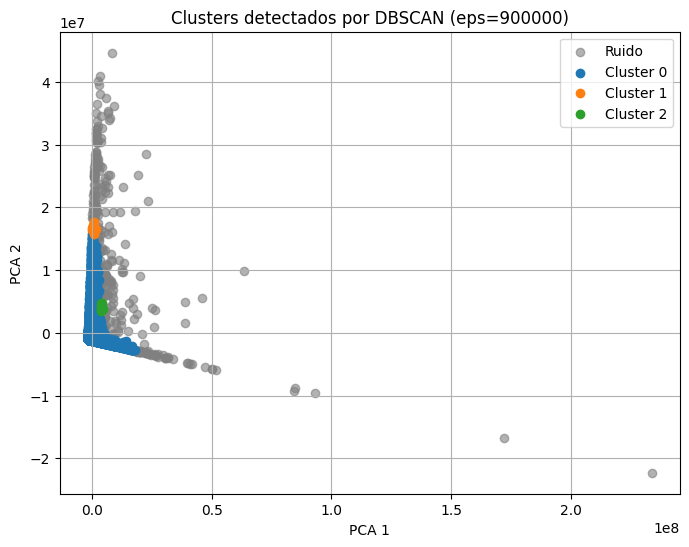

In [31]:

# 2. Se selecciona eps visualmente
eps_val =  900000

# 3. Entrenamiento DBSCAN
dbscan = DBSCAN(eps=eps_val, min_samples=min_samples)
db_labels = dbscan.fit_predict(X)

# 4. Número de clusters detectados (sin contar ruido -1)
n_clusters = len(set(db_labels)) - (1 if -1 in db_labels else 0)
print(f"DBSCAN detectó {n_clusters} clusters")

# 5. Visualización con PCA
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X)

plt.figure(figsize=(8, 6))
for label in np.unique(db_labels):
    if label == -1:
        plt.scatter(X_pca[db_labels == label, 0], X_pca[db_labels == label, 1],
                    c='gray', label='Ruido', alpha=0.6)
    else:
        plt.scatter(X_pca[db_labels == label, 0], X_pca[db_labels == label, 1],
                    label=f'Cluster {label}')
plt.title(f'Clusters detectados por DBSCAN (eps={eps_val})')
plt.xlabel('PCA 1')
plt.ylabel('PCA 2')
plt.legend()
plt.grid(True)
plt.show()

Transacción de prueba 1 pertenecería al Cluster 0
Transacción de prueba 2 pertenecería al Cluster 0
Transacción de prueba 3 pertenecería al Cluster 0


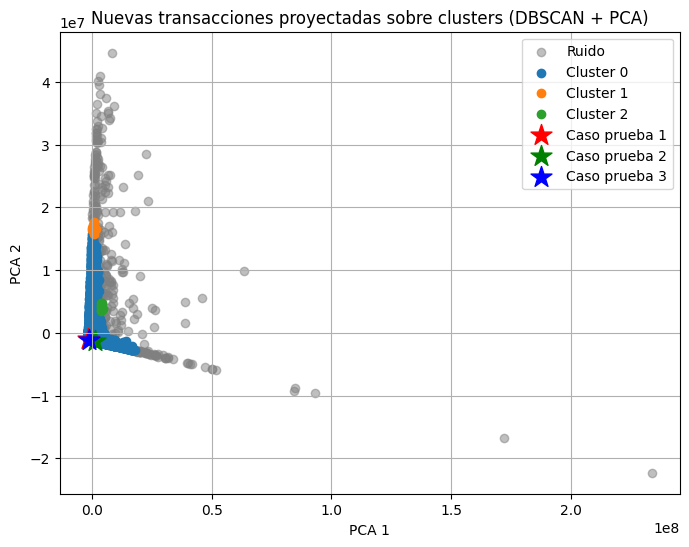

Silhouette score para DBSCAN: 0.5737117969265725


In [32]:

# 6. Casos de prueba (3 transacciones nuevas)
casos_prueba = np.array([
    [10000, 5000, 0, 20000, 30000, 0, 0, 0, 1, 0],      # Caso 1: PAYMENT, valores bajos-medios
    [250000, 100000, 0, 2000000, 2250000, 0, 1, 0, 0, 0], # Caso 2: CASH_OUT, valores muy altos
    [80000, 20000, 0, 400000, 480000, 0, 0, 0, 0, 1]      # Caso 3: TRANSFER, valores intermedios
])

# Predecir a qué cluster (o ruido) pertenece cada transacción de prueba
X_ext = np.vstack([X, casos_prueba])
db_labels_ext = dbscan.fit_predict(X_ext)
casos_predichos = db_labels_ext[-3:]

for i, cluster in enumerate(casos_predichos):
    if cluster == -1:
        print(f"Transacción de prueba {i+1} es considerada ruido (no pertenece a ningún cluster).")
    else:
        print(f"Transacción de prueba {i+1} pertenecería al Cluster {cluster}")

# Proyectar las nuevas transacciones en el espacio PCA
casos_pca = pca.transform(casos_prueba)

plt.figure(figsize=(8, 6))
for label in np.unique(db_labels):
    if label == -1:
        plt.scatter(X_pca[db_labels == label, 0], X_pca[db_labels == label, 1],
                    c='gray', label='Ruido', alpha=0.5)
    else:
        plt.scatter(X_pca[db_labels == label, 0], X_pca[db_labels == label, 1],
                    label=f'Cluster {label}')

colores = ['red', 'green', 'blue']
for i in range(3):
    plt.scatter(casos_pca[i, 0], casos_pca[i, 1], c=colores[i], s=250, marker='*', label=f'Caso prueba {i+1}')

plt.title('Nuevas transacciones proyectadas sobre clusters (DBSCAN + PCA)')
plt.xlabel('PCA 1')
plt.ylabel('PCA 2')
plt.legend()
plt.grid(True)
plt.show()

# 7. Silhouette score para DBSCAN
from sklearn.metrics import silhouette_score
if len(set(db_labels)) - (1 if -1 in db_labels else 0) > 1:
    mask = db_labels != -1
    sil_score = silhouette_score(X[mask], db_labels[mask])
    print(f"Silhouette score para DBSCAN: {sil_score}")
else:
    print("No se puede calcular silhouette score: menos de 2 clusters detectados.")

### Caso 4: CC(SI), ED(NO), Outliers (SI), Balanceo(SI)


#### K-MEANS

Determinamos el número óptimo de clusters con el método del codo y silhouette

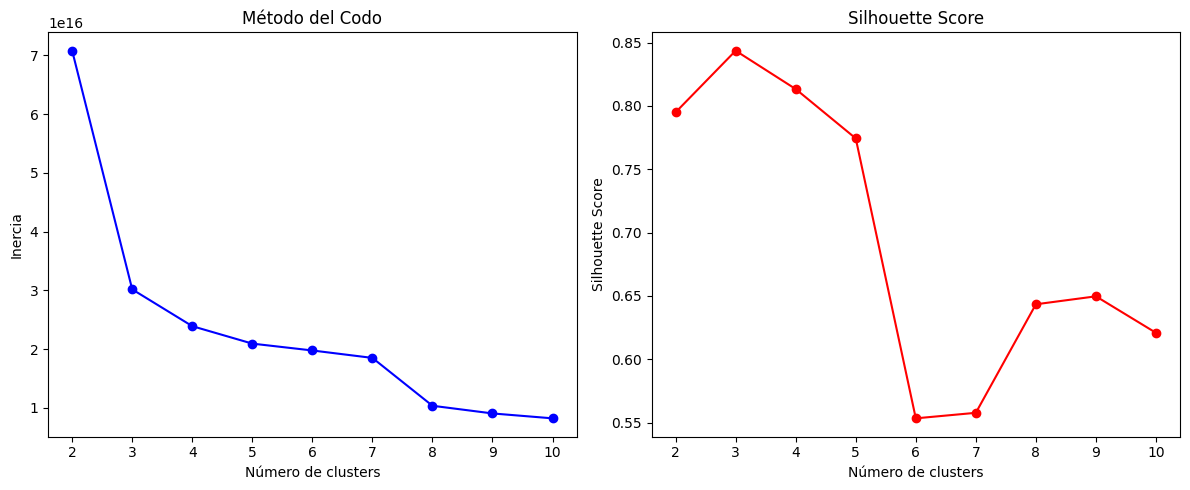

In [33]:
# 1. Cargamos el dataset caso 1
df = pd.read_csv('df_CC_NO_ED_Balanceado_Con_Outliers_Sin_Variable_Objetivo.csv')

# 2 K-Means: Encontrar el número óptimo de clusters
inertia = []
silhouette = []
K = range(2, 11)

for k in K:
    kmeans = KMeans(n_clusters=k, random_state=42)
    labels = kmeans.fit_predict(df)
    inertia.append(kmeans.inertia_)
    silhouette.append(silhouette_score(df, labels))

# Graficar la curva del codo
plt.figure(figsize=(12,5))
plt.subplot(1,2,1)
plt.plot(K, inertia, 'bo-')
plt.xlabel('Número de clusters')
plt.ylabel('Inercia')
plt.title('Método del Codo')

# Graficar el silhouette score
plt.subplot(1,2,2)
plt.plot(K, silhouette, 'ro-')
plt.xlabel('Número de clusters')
plt.ylabel('Silhouette Score')
plt.title('Silhouette Score')
plt.tight_layout()
plt.show()

In [34]:
print("Inercia para cada K:", inertia)
print("Silhouette score para cada K:", silhouette)

# para k=3
print(inertia[1])  # Inercia para k=3
print(silhouette[1])  # Silhouette score para k=3

Inercia para cada K: [7.078105667482653e+16, 3.0169104868030256e+16, 2.390820901968097e+16, 2.0937100722095576e+16, 1.9770434906448132e+16, 1.8505964124048572e+16, 1.0362038948544702e+16, 9055670781279100.0, 8221571770133909.0]
Silhouette score para cada K: [np.float64(0.7950286693247366), np.float64(0.843641161268396), np.float64(0.8133620196013844), np.float64(0.7744080932616004), np.float64(0.553364572680683), np.float64(0.5577313690664686), np.float64(0.6434237737151884), np.float64(0.6497113886625963), np.float64(0.6208850347557456)]
3.0169104868030256e+16
0.843641161268396


##### Justificación del valor de K

El valor óptimo de k es 3, ya que en el método del codo se observa un quiebre claro en ese punto, lo que indica que aumentar el número de clústers después de 3 reduce la inercia de forma menos significativa. Además, el Silhouette Score alcanza su valor máximo en k = 3, lo que indica una excelente cohesión y separación entre clústers,

In [35]:
# el mejor K 
optimal_k = 3

Distancia del primer punto a cada centroide:
[ 6257030.09154075  9159776.20159869 12804184.75331432]
    Centroide 0   Centroide 1   Centroide 2
0  6.257030e+06  9.159776e+06  1.280418e+07
1  5.821439e+05  9.776077e+06  1.615258e+07
2  6.396527e+05  9.777485e+06  1.611231e+07
3  4.624171e+05  9.644044e+06  1.614314e+07
4  6.988675e+05  9.779258e+06  1.628556e+07


c:\Users\Cogito ergo sum\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\base.py:493: UserWarning: X does not have valid feature names, but PCA was fitted with feature names
  warnings.warn(
c:\Users\Cogito ergo sum\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\base.py:493: UserWarning: X does not have valid feature names, but PCA was fitted with feature names
  warnings.warn(


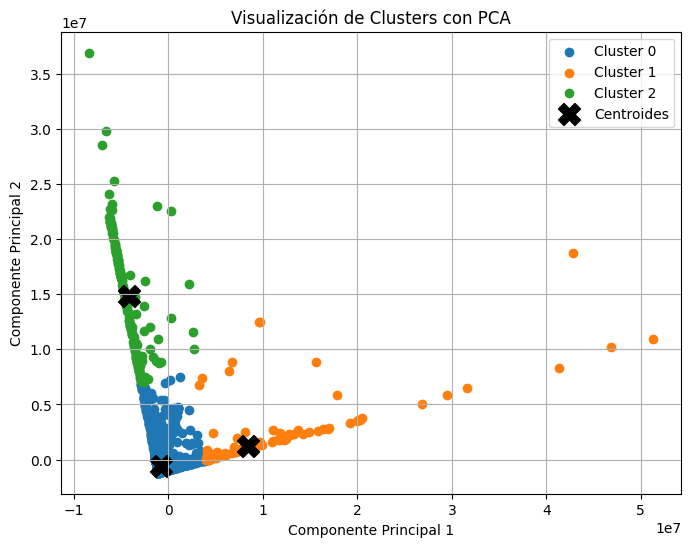

In [36]:
# 2. Entrenar KMeans con el número óptimo de clusters

kmeans = KMeans(n_clusters=optimal_k, random_state=42)
clusters = kmeans.fit_predict(df)

# 3. Calcular distancias a los centroides
distancias = cdist(df, kmeans.cluster_centers_, metric='euclidean')
print("Distancia del primer punto a cada centroide:")
print(distancias[0])

# Visualizar la matriz de distancias
dist_df = pd.DataFrame(distancias, columns=[f"Centroide {i}" for i in range(optimal_k)])
print(dist_df.head())

# 4. Visualización de clusters con PCA
pca = PCA(n_components=2)
X_pca = pca.fit_transform(df)

plt.figure(figsize=(8, 6))
for i in range(optimal_k):
    plt.scatter(X_pca[clusters == i, 0], X_pca[clusters == i, 1], label=f'Cluster {i}')

plt.scatter(pca.transform(kmeans.cluster_centers_)[:, 0],
            pca.transform(kmeans.cluster_centers_)[:, 1],
            s=250, c='black', marker='X', label='Centroides')
plt.title('Visualización de Clusters con PCA')
plt.xlabel('Componente Principal 1')
plt.ylabel('Componente Principal 2')
plt.legend()
plt.grid(True)
plt.show()

In [37]:
# Mostrar los valores de los centroides para cada variable
centroides = pd.DataFrame(kmeans.cluster_centers_, columns=df.columns)
print(centroides)

         amount  oldbalanceOrg  newbalanceOrig  oldbalanceDest  \
0  3.728362e+05   4.244483e+05    8.580226e+04    1.597525e+05   
1  2.095354e+05   2.158979e+05    1.008515e+05    6.809866e+06   
2  5.336379e+06   1.319432e+07    7.955056e+06    3.102912e+05   

   newbalanceDest  type_CASH_IN  type_CASH_OUT    type_DEBIT  type_PAYMENT  \
0    4.120797e+05      0.037707   4.340126e-01  1.904399e-03  7.941345e-02   
1    7.012584e+06      0.027539   9.173838e-01  3.442341e-03  0.000000e+00   
2    2.665534e+05      0.267857  -5.551115e-17 -1.301043e-18 -2.775558e-17   

   type_TRANSFER  
0       0.446962  
1       0.051635  
2       0.732143  


In [38]:
# # Agrega la columna de cluster al DataFrame
# df['cluster'] = clusters

# # Calcula el monto promedio y otras estadísticas por cluster
# resumen = df.groupby('cluster').agg({
#     'amount': ['mean', 'min', 'max', 'count'],
#     'oldbalanceOrg': 'mean',
#     'newbalanceOrig': 'mean'
# })
# print(resumen)

Casos de prueba

Transacción de prueba 1 pertenece al cluster: 0
Transacción de prueba 2 pertenece al cluster: 0
Transacción de prueba 3 pertenece al cluster: 0


c:\Users\Cogito ergo sum\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\base.py:493: UserWarning: X does not have valid feature names, but KMeans was fitted with feature names
  warnings.warn(
c:\Users\Cogito ergo sum\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\base.py:493: UserWarning: X does not have valid feature names, but PCA was fitted with feature names
  warnings.warn(
c:\Users\Cogito ergo sum\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\base.py:493: UserWarning: X does not have valid feature names, but PCA was fitted with feature names
  warnings.warn(
c:\Users\Cogito ergo sum\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\base.py:493: UserWarning: X does not have valid feature names, but PCA was fitted with feature names
  warnings.warn(


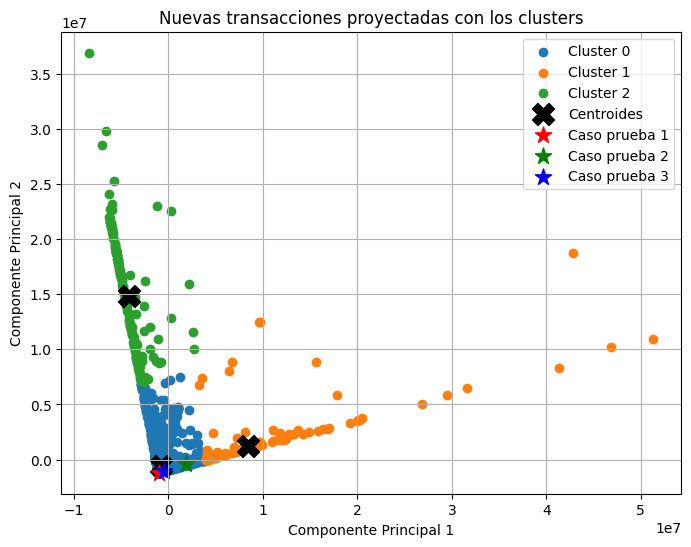

In [39]:
# Se ingresan: amount, oldbalanceOrg, newbalanceOrig, oldbalanceDest, newbalanceDest, type_CASH_IN, type_CASH_OUT, type_DEBIT, type_PAYMENT, type_TRANSFER

# Caso 1: (valores bajos-medios)
caso_1 = [10000, 5000, 0, 20000, 30000, 0, 0, 0, 1, 0]  # PAYMENT

# Caso 2: (valores muy altos)
caso_2 = [250000, 100000, 0, 2000000, 2250000, 0, 1, 0, 0, 0]  # CASH_OUT

# Caso 3: (valores intermedios)
caso_3 = [80000, 20000, 0, 400000, 480000, 0, 0, 0, 0, 1]  # TRANSFER

casos_prueba = np.array([caso_1, caso_2, caso_3])

# Predecir a qué cluster pertenece cada transacción
clusters_predichos = kmeans.predict(casos_prueba)
for i, cluster in enumerate(clusters_predichos):
    print(f"Transacción de prueba {i+1} pertenece al cluster: {cluster}")

# Proyectar las nuevas transacciones en el espacio PCA
casos_pca = pca.transform(casos_prueba)

# Graficar los clusters y las nuevas transacciones
plt.figure(figsize=(8, 6))
for i in range(optimal_k):
    plt.scatter(X_pca[clusters == i, 0], X_pca[clusters == i, 1], label=f'Cluster {i}')

plt.scatter(pca.transform(kmeans.cluster_centers_)[:, 0],
            pca.transform(kmeans.cluster_centers_)[:, 1],
            s=250, c='black', marker='X', label='Centroides')

colores = ['red', 'green', 'blue']
for i in range(3):
    plt.scatter(casos_pca[i, 0], casos_pca[i, 1], c=colores[i], s=150, marker='*', label=f'Caso prueba {i+1}')

plt.title('Nuevas transacciones proyectadas con los clusters')
plt.xlabel('Componente Principal 1')
plt.ylabel('Componente Principal 2')
plt.legend()
plt.grid(True)
plt.show()

##### Interpretación del caso de prueba 1: 

amount: 10000
→ El monto de la transacción es 10,000 unidades monetarias (valor bajo-medio).

oldbalanceOrg: 5000
→ El saldo anterior del origen (quien envía el dinero) es 5,000.

newbalanceOrig: 0
→ El saldo nuevo del origen después de la transacción es 0 (se quedó sin saldo).

oldbalanceDest: 20000
→ El saldo anterior del destino (quien recibe el dinero) es 20,000.

newbalanceDest: 30000
→ El saldo nuevo del destino después de la transacción es 30,000.

type_CASH_IN: 0
→ No es una transacción de tipo CASH_IN.

type_CASH_OUT: 0
→ No es una transacción de tipo CASH_OUT.

type_DEBIT: 0
→ No es una transacción de tipo DEBIT.

type_PAYMENT: 1
→ Es una transacción de tipo PAYMENT (pago).

type_TRANSFER: 0
→ No es una transacción de tipo TRANSFER.

#### DBSCAN

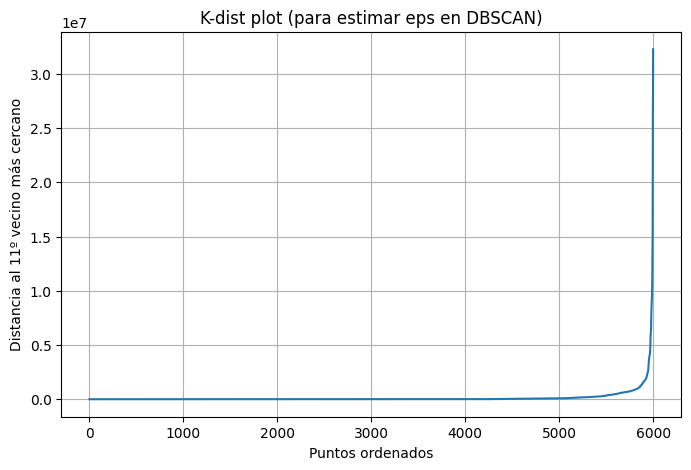

In [40]:
from sklearn.cluster import DBSCAN
from sklearn.neighbors import NearestNeighbors
from sklearn.decomposition import PCA
import numpy as np
import matplotlib.pyplot as plt

# Usamos los datos originales (sin escalar)
X = df.values

# 1. Gráfico K-dist para estimar eps
min_samples = 11  # MinPts = número de features + 1 = 10 + 1 = 11
neighbors = NearestNeighbors(n_neighbors=min_samples)
neighbors_fit = neighbors.fit(X)
distances, indices = neighbors_fit.kneighbors(X)
distances = np.sort(distances[:, min_samples-1])  # Tomamos la 11va distancia más cercana

plt.figure(figsize=(8, 5))
plt.plot(distances)
plt.title('K-dist plot (para estimar eps en DBSCAN)')
plt.xlabel('Puntos ordenados')
plt.ylabel(f'Distancia al {min_samples}º vecino más cercano')
plt.grid(True)
plt.show()


DBSCAN detectó 3 clusters


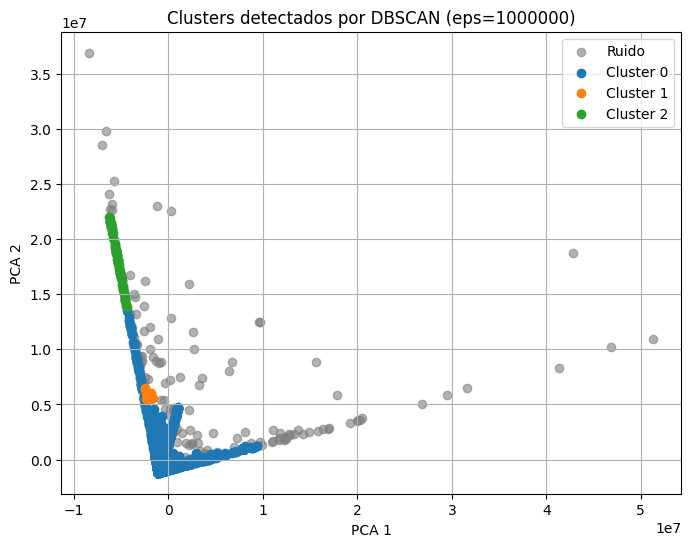

In [41]:

# 2. Se selecciona eps visualmente
eps_val =  1000000 

# 3. Entrenamiento DBSCAN
dbscan = DBSCAN(eps=eps_val, min_samples=min_samples)
db_labels = dbscan.fit_predict(X)

# 4. Número de clusters detectados (sin contar ruido -1)
n_clusters = len(set(db_labels)) - (1 if -1 in db_labels else 0)
print(f"DBSCAN detectó {n_clusters} clusters")

# 5. Visualización con PCA
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X)

plt.figure(figsize=(8, 6))
for label in np.unique(db_labels):
    if label == -1:
        plt.scatter(X_pca[db_labels == label, 0], X_pca[db_labels == label, 1],
                    c='gray', label='Ruido', alpha=0.6)
    else:
        plt.scatter(X_pca[db_labels == label, 0], X_pca[db_labels == label, 1],
                    label=f'Cluster {label}')
plt.title(f'Clusters detectados por DBSCAN (eps={eps_val})')
plt.xlabel('PCA 1')
plt.ylabel('PCA 2')
plt.legend()
plt.grid(True)
plt.show()

Transacción de prueba 1 pertenecería al Cluster 0
Transacción de prueba 2 pertenecería al Cluster 0
Transacción de prueba 3 pertenecería al Cluster 0


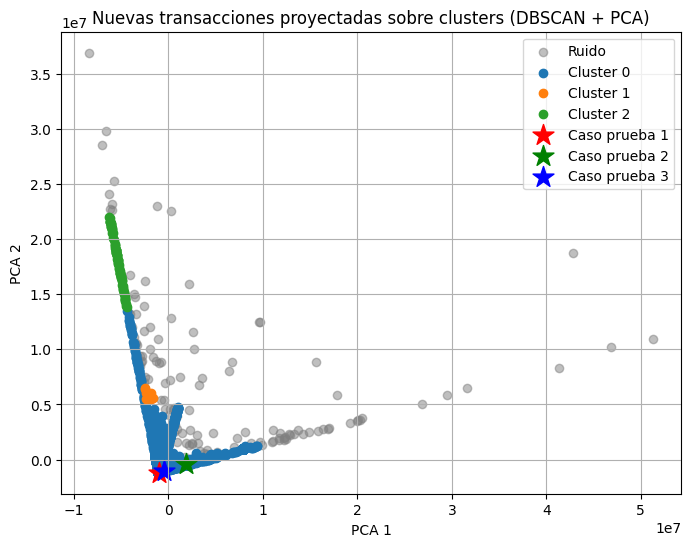

Silhouette score para DBSCAN: 0.6811974505052499


In [42]:

# 6. Casos de prueba (3 transacciones nuevas)
casos_prueba = np.array([
    [10000, 5000, 0, 20000, 30000, 0, 0, 0, 1, 0],      # Caso 1: PAYMENT, valores bajos-medios
    [250000, 100000, 0, 2000000, 2250000, 0, 1, 0, 0, 0], # Caso 2: CASH_OUT, valores muy altos
    [80000, 20000, 0, 400000, 480000, 0, 0, 0, 0, 1]      # Caso 3: TRANSFER, valores intermedios
])

# Predecir a qué cluster (o ruido) pertenece cada transacción de prueba
X_ext = np.vstack([X, casos_prueba])
db_labels_ext = dbscan.fit_predict(X_ext)
casos_predichos = db_labels_ext[-3:]

for i, cluster in enumerate(casos_predichos):
    if cluster == -1:
        print(f"Transacción de prueba {i+1} es considerada ruido (no pertenece a ningún cluster).")
    else:
        print(f"Transacción de prueba {i+1} pertenecería al Cluster {cluster}")

# Proyectar las nuevas transacciones en el espacio PCA
casos_pca = pca.transform(casos_prueba)

plt.figure(figsize=(8, 6))
for label in np.unique(db_labels):
    if label == -1:
        plt.scatter(X_pca[db_labels == label, 0], X_pca[db_labels == label, 1],
                    c='gray', label='Ruido', alpha=0.5)
    else:
        plt.scatter(X_pca[db_labels == label, 0], X_pca[db_labels == label, 1],
                    label=f'Cluster {label}')

colores = ['red', 'green', 'blue']
for i in range(3):
    plt.scatter(casos_pca[i, 0], casos_pca[i, 1], c=colores[i], s=250, marker='*', label=f'Caso prueba {i+1}')

plt.title('Nuevas transacciones proyectadas sobre clusters (DBSCAN + PCA)')
plt.xlabel('PCA 1')
plt.ylabel('PCA 2')
plt.legend()
plt.grid(True)
plt.show()

# 7. Silhouette score para DBSCAN
from sklearn.metrics import silhouette_score
if len(set(db_labels)) - (1 if -1 in db_labels else 0) > 1:
    mask = db_labels != -1
    sil_score = silhouette_score(X[mask], db_labels[mask])
    print(f"Silhouette score para DBSCAN: {sil_score}")
else:
    print("No se puede calcular silhouette score: menos de 2 clusters detectados.")

### Caso 5: CC(SI), ED(SI), Outliers (NO), Balanceo(NO)


#### K-MEANS

Determinamos el número óptimo de clusters con el método del codo y silhouette

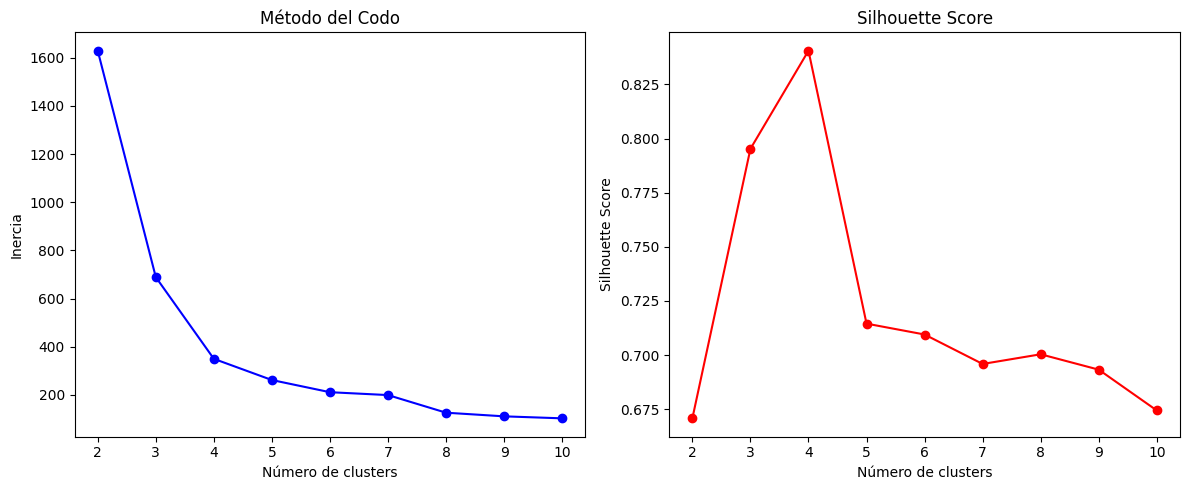

In [43]:
# 1. Cargamos el dataset caso 1
df = pd.read_csv('df_CC_SI_ED_Desbalanceado_Sin_Outliers_Sin_Variable_Objetivo.csv')

# 2 K-Means: Encontrar el número óptimo de clusters
inertia = []
silhouette = []
K = range(2, 11)

for k in K:
    kmeans = KMeans(n_clusters=k, random_state=42)
    labels = kmeans.fit_predict(df)
    inertia.append(kmeans.inertia_)
    silhouette.append(silhouette_score(df, labels))

# Graficar la curva del codo
plt.figure(figsize=(12,5))
plt.subplot(1,2,1)
plt.plot(K, inertia, 'bo-')
plt.xlabel('Número de clusters')
plt.ylabel('Inercia')
plt.title('Método del Codo')

# Graficar el silhouette score
plt.subplot(1,2,2)
plt.plot(K, silhouette, 'ro-')
plt.xlabel('Número de clusters')
plt.ylabel('Silhouette Score')
plt.title('Silhouette Score')
plt.tight_layout()
plt.show()

In [44]:
print("Inercia para cada K:", inertia)
print("Silhouette score para cada K:", silhouette)

# para k=3
print(inertia[2])  # Inercia para k=4
print(silhouette[2])  # Silhouette score para k=4

Inercia para cada K: [1629.4332940002853, 689.036344726189, 349.73651871390905, 261.67581989966305, 211.14909160768792, 199.23970896860024, 126.0393127353168, 110.8907580591641, 102.59114160374448]
Silhouette score para cada K: [np.float64(0.6707778435842127), np.float64(0.7952718942289846), np.float64(0.8406008148316526), np.float64(0.7145285483963458), np.float64(0.7095038599364162), np.float64(0.6958971490944761), np.float64(0.7003716198881493), np.float64(0.6932673331138409), np.float64(0.6744244537018105)]
349.73651871390905
0.8406008148316526


In [45]:
# el mejor K 
optimal_k = 4

Distancia del primer punto a cada centroide:
[1.41850418 1.38021656 1.42359504 0.25266176]
   Centroide 0  Centroide 1  Centroide 2  Centroide 3
0     1.418504     1.380217     1.423595     0.252662
1     1.423500     1.367410     1.419171     0.200001
2     1.436344     1.350369     1.416265     0.112932
3     0.030111     1.410442     1.437202     1.457760
4     1.582993     0.428202     1.514964     1.475360


c:\Users\Cogito ergo sum\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\base.py:493: UserWarning: X does not have valid feature names, but PCA was fitted with feature names
  warnings.warn(
c:\Users\Cogito ergo sum\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\base.py:493: UserWarning: X does not have valid feature names, but PCA was fitted with feature names
  warnings.warn(


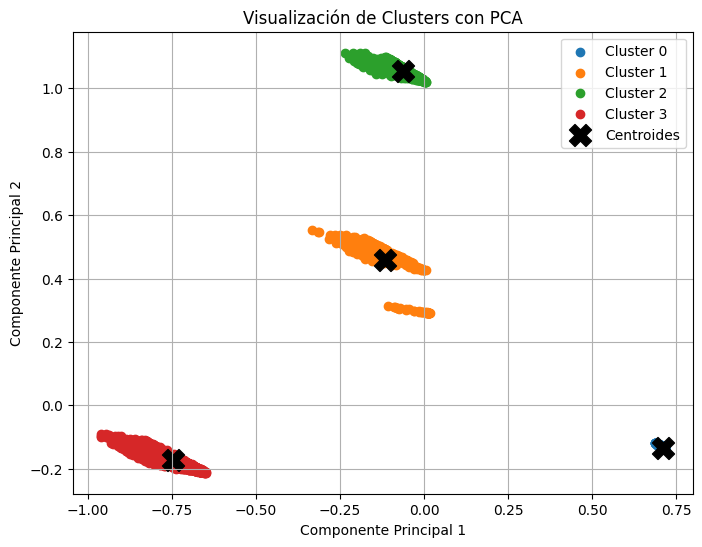

In [46]:
# 2. Entrenar KMeans con el número óptimo de clusters

kmeans = KMeans(n_clusters=optimal_k, random_state=42)
clusters = kmeans.fit_predict(df)

# 3. Calcular distancias a los centroides
distancias = cdist(df, kmeans.cluster_centers_, metric='euclidean')
print("Distancia del primer punto a cada centroide:")
print(distancias[0])

# Visualizar la matriz de distancias
dist_df = pd.DataFrame(distancias, columns=[f"Centroide {i}" for i in range(optimal_k)])
print(dist_df.head())

# 4. Visualización de clusters con PCA
pca = PCA(n_components=2)
X_pca = pca.fit_transform(df)

plt.figure(figsize=(8, 6))
for i in range(optimal_k):
    plt.scatter(X_pca[clusters == i, 0], X_pca[clusters == i, 1], label=f'Cluster {i}')

plt.scatter(pca.transform(kmeans.cluster_centers_)[:, 0],
            pca.transform(kmeans.cluster_centers_)[:, 1],
            s=250, c='black', marker='X', label='Centroides')
plt.title('Visualización de Clusters con PCA')
plt.xlabel('Componente Principal 1')
plt.ylabel('Componente Principal 2')
plt.legend()
plt.grid(True)
plt.show()

In [47]:
# Mostrar los valores de los centroides para cada variable
centroides = pd.DataFrame(kmeans.cluster_centers_, columns=df.columns)
print(centroides)

     amount  oldbalanceOrg  newbalanceOrig  oldbalanceDest  newbalanceDest  \
0 -0.292059      -0.279768       -0.285887       -0.309000       -0.326398   
1  0.064158      -0.282384       -0.294154       -0.131036       -0.096416   
2 -0.069172      -0.279738       -0.234551       -0.209441       -0.248123   
3 -0.036035      -0.283593       -0.294852       -0.155854       -0.135302   

   type_CASH_IN  type_CASH_OUT    type_DEBIT  type_PAYMENT  type_TRANSFER  
0 -7.494005e-16  -7.216450e-16 -3.382711e-17  1.000000e+00   2.151057e-16  
1  6.938894e-17   1.665335e-16  1.263538e-01  2.220446e-16   8.736462e-01  
2  1.000000e+00   1.665335e-16  4.336809e-18 -1.665335e-16   6.245005e-17  
3 -6.661338e-16   1.000000e+00 -3.295975e-17 -7.771561e-16   1.665335e-16  


In [48]:
# # Agrega la columna de cluster al DataFrame
# df['cluster'] = clusters

# # Calcula el monto promedio y otras estadísticas por cluster
# resumen = df.groupby('cluster').agg({
#     'amount': ['mean', 'min', 'max', 'count'],
#     'oldbalanceOrg': 'mean',
#     'newbalanceOrig': 'mean'
# })
# print(resumen)

Casos de prueba

Transacción de prueba 1 pertenece al cluster: 1
Transacción de prueba 2 pertenece al cluster: 1
Transacción de prueba 3 pertenece al cluster: 1


c:\Users\Cogito ergo sum\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\base.py:493: UserWarning: X does not have valid feature names, but KMeans was fitted with feature names
  warnings.warn(
c:\Users\Cogito ergo sum\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\base.py:493: UserWarning: X does not have valid feature names, but PCA was fitted with feature names
  warnings.warn(
c:\Users\Cogito ergo sum\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\base.py:493: UserWarning: X does not have valid feature names, but PCA was fitted with feature names
  warnings.warn(
c:\Users\Cogito ergo sum\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\base.py:493: UserWarning: X does not have valid feature names, but PCA was fitted with feature names
  warnings.warn(


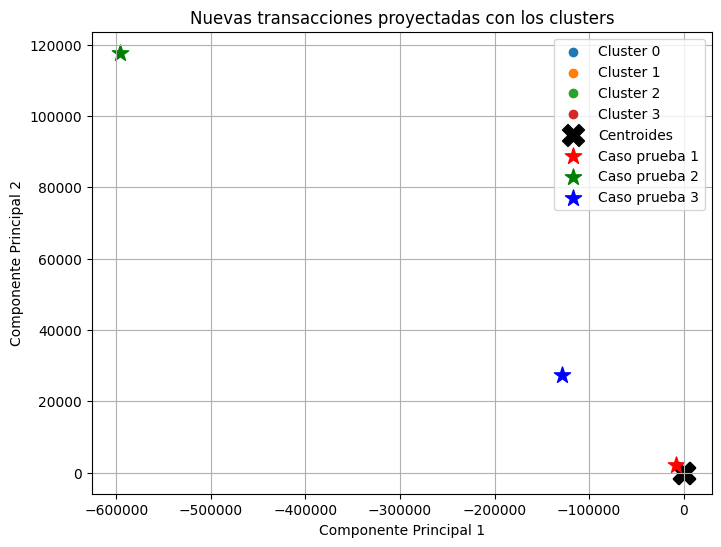

In [49]:
# Se ingresan: amount, oldbalanceOrg, newbalanceOrig, oldbalanceDest, newbalanceDest, type_CASH_IN, type_CASH_OUT, type_DEBIT, type_PAYMENT, type_TRANSFER

# Caso 1: (valores bajos-medios)
caso_1 = [10000, 5000, 0, 20000, 30000, 0, 0, 0, 1, 0]  # PAYMENT

# Caso 2: (valores muy altos)
caso_2 = [250000, 100000, 0, 2000000, 2250000, 0, 1, 0, 0, 0]  # CASH_OUT

# Caso 3: (valores intermedios)
caso_3 = [80000, 20000, 0, 400000, 480000, 0, 0, 0, 0, 1]  # TRANSFER

casos_prueba = np.array([caso_1, caso_2, caso_3])

# Predecir a qué cluster pertenece cada transacción
clusters_predichos = kmeans.predict(casos_prueba)
for i, cluster in enumerate(clusters_predichos):
    print(f"Transacción de prueba {i+1} pertenece al cluster: {cluster}")

# Proyectar las nuevas transacciones en el espacio PCA
casos_pca = pca.transform(casos_prueba)

# Graficar los clusters y las nuevas transacciones
plt.figure(figsize=(8, 6))
for i in range(optimal_k):
    plt.scatter(X_pca[clusters == i, 0], X_pca[clusters == i, 1], label=f'Cluster {i}')

plt.scatter(pca.transform(kmeans.cluster_centers_)[:, 0],
            pca.transform(kmeans.cluster_centers_)[:, 1],
            s=250, c='black', marker='X', label='Centroides')

colores = ['red', 'green', 'blue']
for i in range(3):
    plt.scatter(casos_pca[i, 0], casos_pca[i, 1], c=colores[i], s=150, marker='*', label=f'Caso prueba {i+1}')

plt.title('Nuevas transacciones proyectadas con los clusters')
plt.xlabel('Componente Principal 1')
plt.ylabel('Componente Principal 2')
plt.legend()
plt.grid(True)
plt.show()

##### Interpretación del caso de prueba 1: 

amount: 10000
→ El monto de la transacción es 10,000 unidades monetarias (valor bajo-medio).

oldbalanceOrg: 5000
→ El saldo anterior del origen (quien envía el dinero) es 5,000.

newbalanceOrig: 0
→ El saldo nuevo del origen después de la transacción es 0 (se quedó sin saldo).

oldbalanceDest: 20000
→ El saldo anterior del destino (quien recibe el dinero) es 20,000.

newbalanceDest: 30000
→ El saldo nuevo del destino después de la transacción es 30,000.

type_CASH_IN: 0
→ No es una transacción de tipo CASH_IN.

type_CASH_OUT: 0
→ No es una transacción de tipo CASH_OUT.

type_DEBIT: 0
→ No es una transacción de tipo DEBIT.

type_PAYMENT: 1
→ Es una transacción de tipo PAYMENT (pago).

type_TRANSFER: 0
→ No es una transacción de tipo TRANSFER.

#### DBSCAN

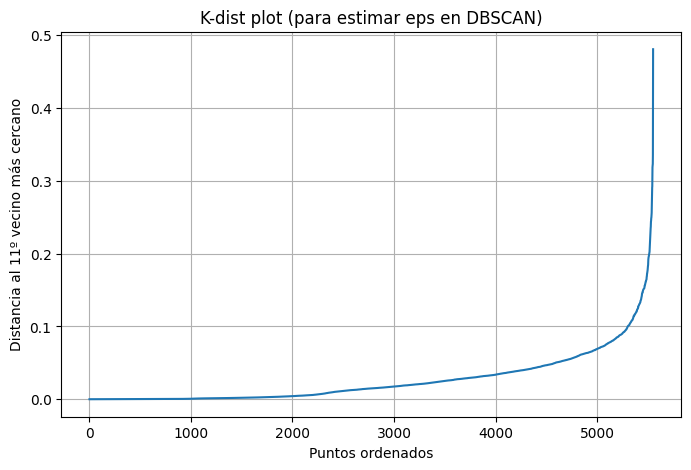

In [50]:
from sklearn.cluster import DBSCAN
from sklearn.neighbors import NearestNeighbors
from sklearn.decomposition import PCA
import numpy as np
import matplotlib.pyplot as plt

# Usamos los datos originales (sin escalar)
X = df.values

# 1. Gráfico K-dist para estimar eps
min_samples = 11  # MinPts = número de features + 1 = 10 + 1 = 11
neighbors = NearestNeighbors(n_neighbors=min_samples)
neighbors_fit = neighbors.fit(X)
distances, indices = neighbors_fit.kneighbors(X)
distances = np.sort(distances[:, min_samples-1])  # Tomamos la 11va distancia más cercana

plt.figure(figsize=(8, 5))
plt.plot(distances)
plt.title('K-dist plot (para estimar eps en DBSCAN)')
plt.xlabel('Puntos ordenados')
plt.ylabel(f'Distancia al {min_samples}º vecino más cercano')
plt.grid(True)
plt.show()


DBSCAN detectó 5 clusters


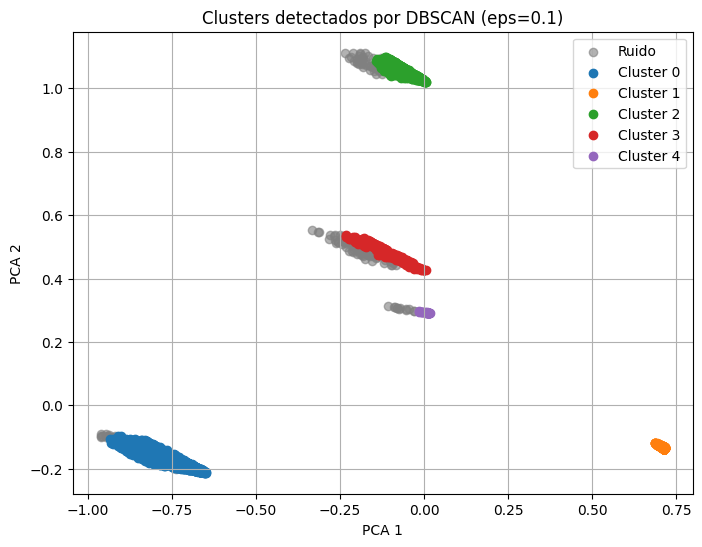

In [51]:

# 2. Se selecciona eps visualmente
eps_val =  0.1

# 3. Entrenamiento DBSCAN
dbscan = DBSCAN(eps=eps_val, min_samples=min_samples)
db_labels = dbscan.fit_predict(X)

# 4. Número de clusters detectados (sin contar ruido -1)
n_clusters = len(set(db_labels)) - (1 if -1 in db_labels else 0)
print(f"DBSCAN detectó {n_clusters} clusters")

# 5. Visualización con PCA
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X)

plt.figure(figsize=(8, 6))
for label in np.unique(db_labels):
    if label == -1:
        plt.scatter(X_pca[db_labels == label, 0], X_pca[db_labels == label, 1],
                    c='gray', label='Ruido', alpha=0.6)
    else:
        plt.scatter(X_pca[db_labels == label, 0], X_pca[db_labels == label, 1],
                    label=f'Cluster {label}')
plt.title(f'Clusters detectados por DBSCAN (eps={eps_val})')
plt.xlabel('PCA 1')
plt.ylabel('PCA 2')
plt.legend()
plt.grid(True)
plt.show()

Transacción de prueba 1 es considerada ruido (no pertenece a ningún cluster).
Transacción de prueba 2 es considerada ruido (no pertenece a ningún cluster).
Transacción de prueba 3 es considerada ruido (no pertenece a ningún cluster).


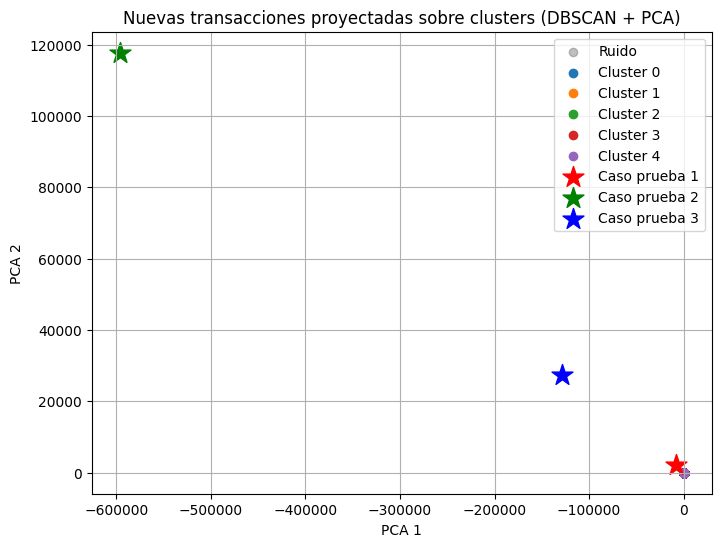

Silhouette score para DBSCAN: 0.8596316073638809


In [52]:

# 6. Casos de prueba (3 transacciones nuevas)
casos_prueba = np.array([
    [10000, 5000, 0, 20000, 30000, 0, 0, 0, 1, 0],      # Caso 1: PAYMENT, valores bajos-medios
    [250000, 100000, 0, 2000000, 2250000, 0, 1, 0, 0, 0], # Caso 2: CASH_OUT, valores muy altos
    [80000, 20000, 0, 400000, 480000, 0, 0, 0, 0, 1]      # Caso 3: TRANSFER, valores intermedios
])

# Predecir a qué cluster (o ruido) pertenece cada transacción de prueba
X_ext = np.vstack([X, casos_prueba])
db_labels_ext = dbscan.fit_predict(X_ext)
casos_predichos = db_labels_ext[-3:]

for i, cluster in enumerate(casos_predichos):
    if cluster == -1:
        print(f"Transacción de prueba {i+1} es considerada ruido (no pertenece a ningún cluster).")
    else:
        print(f"Transacción de prueba {i+1} pertenecería al Cluster {cluster}")

# Proyectar las nuevas transacciones en el espacio PCA
casos_pca = pca.transform(casos_prueba)

plt.figure(figsize=(8, 6))
for label in np.unique(db_labels):
    if label == -1:
        plt.scatter(X_pca[db_labels == label, 0], X_pca[db_labels == label, 1],
                    c='gray', label='Ruido', alpha=0.5)
    else:
        plt.scatter(X_pca[db_labels == label, 0], X_pca[db_labels == label, 1],
                    label=f'Cluster {label}')

colores = ['red', 'green', 'blue']
for i in range(3):
    plt.scatter(casos_pca[i, 0], casos_pca[i, 1], c=colores[i], s=250, marker='*', label=f'Caso prueba {i+1}')

plt.title('Nuevas transacciones proyectadas sobre clusters (DBSCAN + PCA)')
plt.xlabel('PCA 1')
plt.ylabel('PCA 2')
plt.legend()
plt.grid(True)
plt.show()

# 7. Silhouette score para DBSCAN
from sklearn.metrics import silhouette_score
if len(set(db_labels)) - (1 if -1 in db_labels else 0) > 1:
    mask = db_labels != -1
    sil_score = silhouette_score(X[mask], db_labels[mask])
    print(f"Silhouette score para DBSCAN: {sil_score}")
else:
    print("No se puede calcular silhouette score: menos de 2 clusters detectados.")

### Caso 6: CC(SI), ED(SI), Outliers (NO), Balanceo(SI)


#### K-MEANS

Determinamos el número óptimo de clusters con el método del codo y silhouette

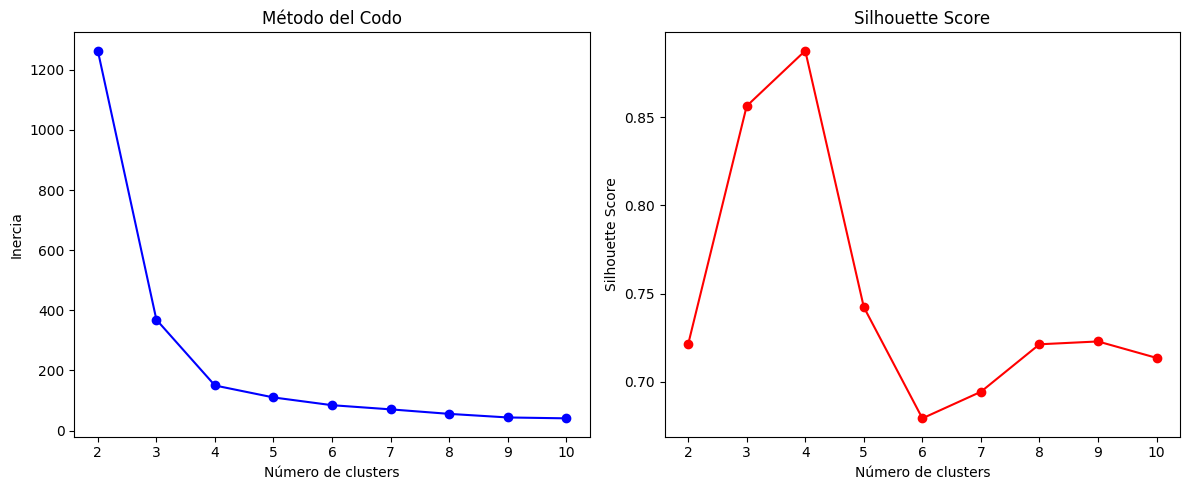

In [53]:
# 1. Cargamos el dataset caso 1
df = pd.read_csv('df_CC_SI_ED_Balanceado_Sin_Outliers_Sin_Variable_Objetivo.csv')

# 2 K-Means: Encontrar el número óptimo de clusters
inertia = []
silhouette = []
K = range(2, 11)

for k in K:
    kmeans = KMeans(n_clusters=k, random_state=42)
    labels = kmeans.fit_predict(df)
    inertia.append(kmeans.inertia_)
    silhouette.append(silhouette_score(df, labels))

# Graficar la curva del codo
plt.figure(figsize=(12,5))
plt.subplot(1,2,1)
plt.plot(K, inertia, 'bo-')
plt.xlabel('Número de clusters')
plt.ylabel('Inercia')
plt.title('Método del Codo')

# Graficar el silhouette score
plt.subplot(1,2,2)
plt.plot(K, silhouette, 'ro-')
plt.xlabel('Número de clusters')
plt.ylabel('Silhouette Score')
plt.title('Silhouette Score')
plt.tight_layout()
plt.show()

In [54]:
print("Inercia para cada K:", inertia)
print("Silhouette score para cada K:", silhouette)

# para k=4
print(inertia[2])  # Inercia para k=4
print(silhouette[2])  # Silhouette score para k=4

Inercia para cada K: [1263.436821465531, 368.9076249233693, 149.96465802758308, 110.19884209742436, 84.41674014009264, 70.54518376580573, 55.569433937191256, 43.63110728890109, 40.68715345458248]
Silhouette score para cada K: [np.float64(0.7212160971766366), np.float64(0.8563946352689156), np.float64(0.8877732612463002), np.float64(0.7423401844676505), np.float64(0.6792303726447511), np.float64(0.694303700552362), np.float64(0.7212338409944772), np.float64(0.722850199325943), np.float64(0.7135203838929731)]
149.96465802758308
0.8877732612463002


##### Justificación del valor de K

El valor óptimo de k es 3, ya que en el método del codo se observa un quiebre claro en ese punto, lo que indica que aumentar el número de clústers después de 3 reduce la inercia de forma menos significativa. Además, el Silhouette Score alcanza su valor máximo en k = 3, lo que indica una excelente cohesión y separación entre clústers,

In [55]:
# el mejor K 
optimal_k = 4

Distancia del primer punto a cada centroide:
[1.41486597 0.1289172  1.42718293 1.39204941]
   Centroide 0  Centroide 1  Centroide 2  Centroide 3
0     1.414866     0.128917     1.427183     1.392049
1     0.128110     1.423780     1.442554     1.394131
2     1.425544     1.442318     0.026999     1.415467
3     1.414856     0.129012     1.427127     1.392062
4     0.143503     1.436773     1.414365     1.409570


c:\Users\Cogito ergo sum\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\base.py:493: UserWarning: X does not have valid feature names, but PCA was fitted with feature names
  warnings.warn(
c:\Users\Cogito ergo sum\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\base.py:493: UserWarning: X does not have valid feature names, but PCA was fitted with feature names
  warnings.warn(


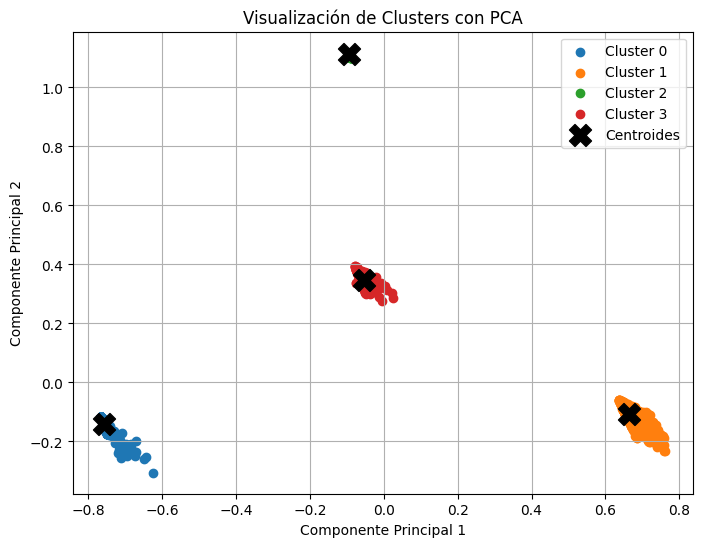

In [56]:
# 2. Entrenar KMeans con el número óptimo de clusters

kmeans = KMeans(n_clusters=optimal_k, random_state=42)
clusters = kmeans.fit_predict(df)

# 3. Calcular distancias a los centroides
distancias = cdist(df, kmeans.cluster_centers_, metric='euclidean')
print("Distancia del primer punto a cada centroide:")
print(distancias[0])

# Visualizar la matriz de distancias
dist_df = pd.DataFrame(distancias, columns=[f"Centroide {i}" for i in range(optimal_k)])
print(dist_df.head())

# 4. Visualización de clusters con PCA
pca = PCA(n_components=2)
X_pca = pca.fit_transform(df)

plt.figure(figsize=(8, 6))
for i in range(optimal_k):
    plt.scatter(X_pca[clusters == i, 0], X_pca[clusters == i, 1], label=f'Cluster {i}')

plt.scatter(pca.transform(kmeans.cluster_centers_)[:, 0],
            pca.transform(kmeans.cluster_centers_)[:, 1],
            s=250, c='black', marker='X', label='Centroides')
plt.title('Visualización de Clusters con PCA')
plt.xlabel('Componente Principal 1')
plt.ylabel('Componente Principal 2')
plt.legend()
plt.grid(True)
plt.show()

In [57]:
# Mostrar los valores de los centroides para cada variable
centroides = pd.DataFrame(kmeans.cluster_centers_, columns=df.columns)
print(centroides)

     amount  oldbalanceOrg  newbalanceOrig  oldbalanceDest  newbalanceDest  \
0 -0.136650      -0.257944       -0.296457       -0.305725       -0.322084   
1 -0.075824      -0.252095       -0.296246       -0.221015       -0.204616   
2 -0.291938      -0.277501       -0.283827       -0.309000       -0.326398   
3 -0.058538      -0.280629       -0.233352       -0.202053       -0.244554   

   type_CASH_IN  type_CASH_OUT    type_DEBIT  type_PAYMENT  type_TRANSFER  
0 -4.163336e-17  -3.941292e-15 -6.505213e-19  1.110223e-16   1.000000e+00  
1 -7.285839e-17   1.000000e+00 -8.673617e-19  0.000000e+00   3.608225e-15  
2 -1.387779e-17  -5.551115e-17 -6.505213e-19  1.000000e+00  -3.330669e-16  
3  9.565217e-01   0.000000e+00  4.347826e-02 -1.387779e-17  -1.110223e-16  


In [58]:
# # Agrega la columna de cluster al DataFrame
# df['cluster'] = clusters

# # Calcula el monto promedio y otras estadísticas por cluster
# resumen = df.groupby('cluster').agg({
#     'amount': ['mean', 'min', 'max', 'count'],
#     'oldbalanceOrg': 'mean',
#     'newbalanceOrig': 'mean'
# })
# print(resumen)

Casos de prueba

Transacción de prueba 1 pertenece al cluster: 1
Transacción de prueba 2 pertenece al cluster: 1
Transacción de prueba 3 pertenece al cluster: 1


c:\Users\Cogito ergo sum\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\base.py:493: UserWarning: X does not have valid feature names, but KMeans was fitted with feature names
  warnings.warn(
c:\Users\Cogito ergo sum\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\base.py:493: UserWarning: X does not have valid feature names, but PCA was fitted with feature names
  warnings.warn(
c:\Users\Cogito ergo sum\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\base.py:493: UserWarning: X does not have valid feature names, but PCA was fitted with feature names
  warnings.warn(
c:\Users\Cogito ergo sum\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\base.py:493: UserWarning: X does not have valid feature names, but PCA was fitted with feature names
  warnings.warn(


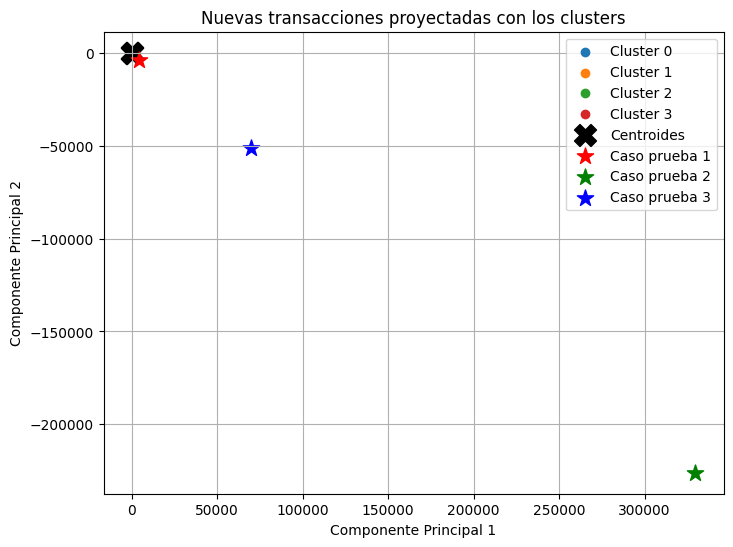

In [59]:
# Se ingresan: amount, oldbalanceOrg, newbalanceOrig, oldbalanceDest, newbalanceDest, type_CASH_IN, type_CASH_OUT, type_DEBIT, type_PAYMENT, type_TRANSFER

# Caso 1: (valores bajos-medios)
caso_1 = [10000, 5000, 0, 20000, 30000, 0, 0, 0, 1, 0]  # PAYMENT

# Caso 2: (valores muy altos)
caso_2 = [250000, 100000, 0, 2000000, 2250000, 0, 1, 0, 0, 0]  # CASH_OUT

# Caso 3: (valores intermedios)
caso_3 = [80000, 20000, 0, 400000, 480000, 0, 0, 0, 0, 1]  # TRANSFER

casos_prueba = np.array([caso_1, caso_2, caso_3])

# Predecir a qué cluster pertenece cada transacción
clusters_predichos = kmeans.predict(casos_prueba)
for i, cluster in enumerate(clusters_predichos):
    print(f"Transacción de prueba {i+1} pertenece al cluster: {cluster}")

# Proyectar las nuevas transacciones en el espacio PCA
casos_pca = pca.transform(casos_prueba)

# Graficar los clusters y las nuevas transacciones
plt.figure(figsize=(8, 6))
for i in range(optimal_k):
    plt.scatter(X_pca[clusters == i, 0], X_pca[clusters == i, 1], label=f'Cluster {i}')

plt.scatter(pca.transform(kmeans.cluster_centers_)[:, 0],
            pca.transform(kmeans.cluster_centers_)[:, 1],
            s=250, c='black', marker='X', label='Centroides')

colores = ['red', 'green', 'blue']
for i in range(3):
    plt.scatter(casos_pca[i, 0], casos_pca[i, 1], c=colores[i], s=150, marker='*', label=f'Caso prueba {i+1}')

plt.title('Nuevas transacciones proyectadas con los clusters')
plt.xlabel('Componente Principal 1')
plt.ylabel('Componente Principal 2')
plt.legend()
plt.grid(True)
plt.show()

##### Interpretación del caso de prueba 1: 

amount: 10000
→ El monto de la transacción es 10,000 unidades monetarias (valor bajo-medio).

oldbalanceOrg: 5000
→ El saldo anterior del origen (quien envía el dinero) es 5,000.

newbalanceOrig: 0
→ El saldo nuevo del origen después de la transacción es 0 (se quedó sin saldo).

oldbalanceDest: 20000
→ El saldo anterior del destino (quien recibe el dinero) es 20,000.

newbalanceDest: 30000
→ El saldo nuevo del destino después de la transacción es 30,000.

type_CASH_IN: 0
→ No es una transacción de tipo CASH_IN.

type_CASH_OUT: 0
→ No es una transacción de tipo CASH_OUT.

type_DEBIT: 0
→ No es una transacción de tipo DEBIT.

type_PAYMENT: 1
→ Es una transacción de tipo PAYMENT (pago).

type_TRANSFER: 0
→ No es una transacción de tipo TRANSFER.

#### DBSCAN

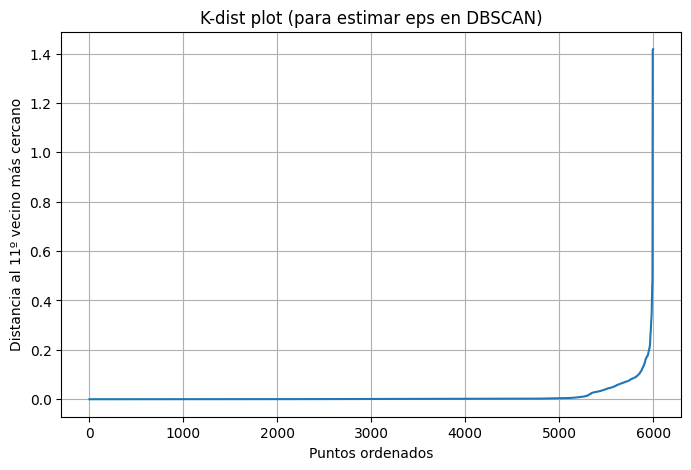

In [60]:
from sklearn.cluster import DBSCAN
from sklearn.neighbors import NearestNeighbors
from sklearn.decomposition import PCA
import numpy as np
import matplotlib.pyplot as plt

# Usamos los datos originales (sin escalar)
X = df.values

# 1. Gráfico K-dist para estimar eps
min_samples = 11  # MinPts = número de features + 1 = 10 + 1 = 11
neighbors = NearestNeighbors(n_neighbors=min_samples)
neighbors_fit = neighbors.fit(X)
distances, indices = neighbors_fit.kneighbors(X)
distances = np.sort(distances[:, min_samples-1])  # Tomamos la 11va distancia más cercana

plt.figure(figsize=(8, 5))
plt.plot(distances)
plt.title('K-dist plot (para estimar eps en DBSCAN)')
plt.xlabel('Puntos ordenados')
plt.ylabel(f'Distancia al {min_samples}º vecino más cercano')
plt.grid(True)
plt.show()


DBSCAN detectó 5 clusters


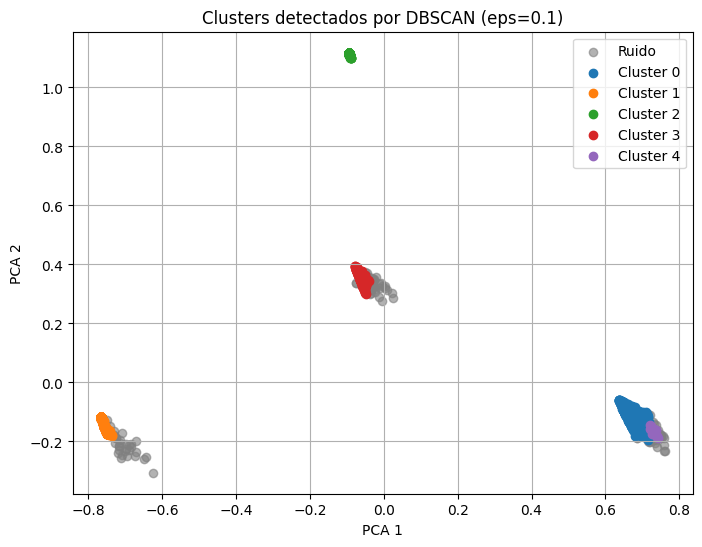

In [61]:

# 2. Se selecciona eps visualmente
eps_val =  0.1 # Usando el valor sugerido (0.2*10^6)

# 3. Entrenamiento DBSCAN
dbscan = DBSCAN(eps=eps_val, min_samples=min_samples)
db_labels = dbscan.fit_predict(X)

# 4. Número de clusters detectados (sin contar ruido -1)
n_clusters = len(set(db_labels)) - (1 if -1 in db_labels else 0)
print(f"DBSCAN detectó {n_clusters} clusters")

# 5. Visualización con PCA
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X)

plt.figure(figsize=(8, 6))
for label in np.unique(db_labels):
    if label == -1:
        plt.scatter(X_pca[db_labels == label, 0], X_pca[db_labels == label, 1],
                    c='gray', label='Ruido', alpha=0.6)
    else:
        plt.scatter(X_pca[db_labels == label, 0], X_pca[db_labels == label, 1],
                    label=f'Cluster {label}')
plt.title(f'Clusters detectados por DBSCAN (eps={eps_val})')
plt.xlabel('PCA 1')
plt.ylabel('PCA 2')
plt.legend()
plt.grid(True)
plt.show()

Transacción de prueba 1 es considerada ruido (no pertenece a ningún cluster).
Transacción de prueba 2 es considerada ruido (no pertenece a ningún cluster).
Transacción de prueba 3 es considerada ruido (no pertenece a ningún cluster).


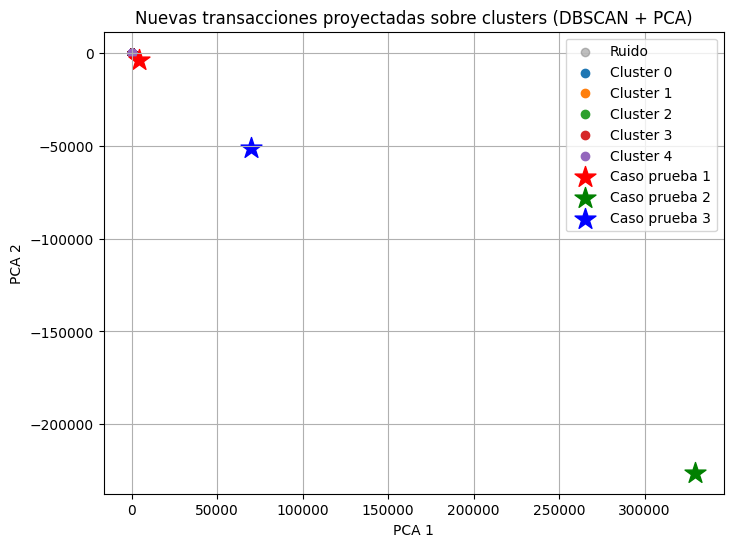

Silhouette score para DBSCAN: 0.806862760233461


In [62]:

# 6. Casos de prueba (3 transacciones nuevas)
casos_prueba = np.array([
    [10000, 5000, 0, 20000, 30000, 0, 0, 0, 1, 0],      # Caso 1: PAYMENT, valores bajos-medios
    [250000, 100000, 0, 2000000, 2250000, 0, 1, 0, 0, 0], # Caso 2: CASH_OUT, valores muy altos
    [80000, 20000, 0, 400000, 480000, 0, 0, 0, 0, 1]      # Caso 3: TRANSFER, valores intermedios
])

# Predecir a qué cluster (o ruido) pertenece cada transacción de prueba
X_ext = np.vstack([X, casos_prueba])
db_labels_ext = dbscan.fit_predict(X_ext)
casos_predichos = db_labels_ext[-3:]

for i, cluster in enumerate(casos_predichos):
    if cluster == -1:
        print(f"Transacción de prueba {i+1} es considerada ruido (no pertenece a ningún cluster).")
    else:
        print(f"Transacción de prueba {i+1} pertenecería al Cluster {cluster}")

# Proyectar las nuevas transacciones en el espacio PCA
casos_pca = pca.transform(casos_prueba)

plt.figure(figsize=(8, 6))
for label in np.unique(db_labels):
    if label == -1:
        plt.scatter(X_pca[db_labels == label, 0], X_pca[db_labels == label, 1],
                    c='gray', label='Ruido', alpha=0.5)
    else:
        plt.scatter(X_pca[db_labels == label, 0], X_pca[db_labels == label, 1],
                    label=f'Cluster {label}')

colores = ['red', 'green', 'blue']
for i in range(3):
    plt.scatter(casos_pca[i, 0], casos_pca[i, 1], c=colores[i], s=250, marker='*', label=f'Caso prueba {i+1}')

plt.title('Nuevas transacciones proyectadas sobre clusters (DBSCAN + PCA)')
plt.xlabel('PCA 1')
plt.ylabel('PCA 2')
plt.legend()
plt.grid(True)
plt.show()

# 7. Silhouette score para DBSCAN
from sklearn.metrics import silhouette_score
if len(set(db_labels)) - (1 if -1 in db_labels else 0) > 1:
    mask = db_labels != -1
    sil_score = silhouette_score(X[mask], db_labels[mask])
    print(f"Silhouette score para DBSCAN: {sil_score}")
else:
    print("No se puede calcular silhouette score: menos de 2 clusters detectados.")

### Caso 7: CC(SI), ED(SI), Outliers (SI), Balanceo(NO)


#### K-MEANS

Determinamos el número óptimo de clusters con el método del codo y silhouette

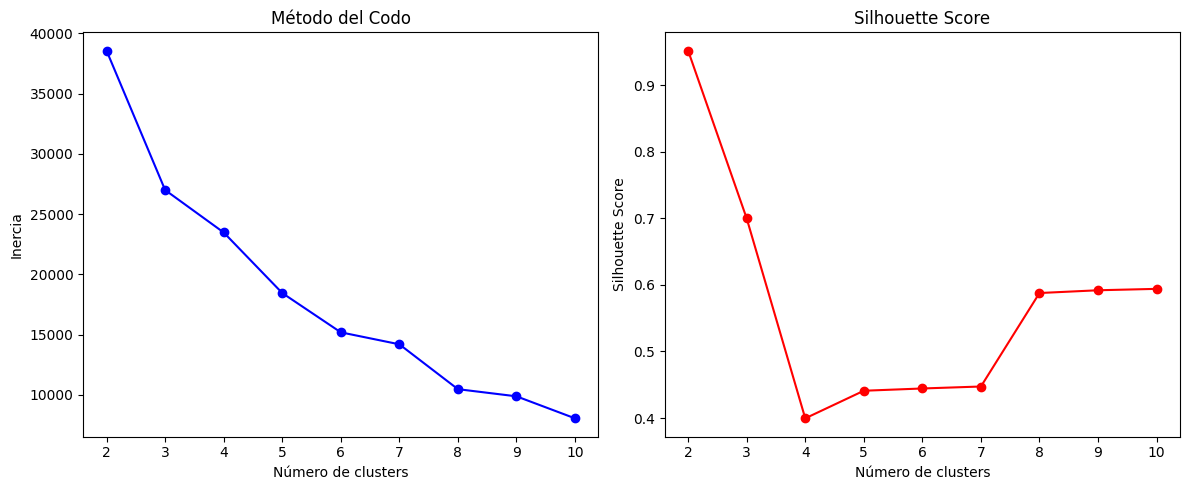

In [63]:
# 1. Cargamos el dataset caso 1
df = pd.read_csv('df_CC_SI_ED_Desbalanceado_Con_Outliers_Sin_Variable_Objetivo.csv')

# 2 K-Means: Encontrar el número óptimo de clusters
inertia = []
silhouette = []
K = range(2, 11)

for k in K:
    kmeans = KMeans(n_clusters=k, random_state=42)
    labels = kmeans.fit_predict(df)
    inertia.append(kmeans.inertia_)
    silhouette.append(silhouette_score(df, labels))

# Graficar la curva del codo
plt.figure(figsize=(12,5))
plt.subplot(1,2,1)
plt.plot(K, inertia, 'bo-')
plt.xlabel('Número de clusters')
plt.ylabel('Inercia')
plt.title('Método del Codo')

# Graficar el silhouette score
plt.subplot(1,2,2)
plt.plot(K, silhouette, 'ro-')
plt.xlabel('Número de clusters')
plt.ylabel('Silhouette Score')
plt.title('Silhouette Score')
plt.tight_layout()
plt.show()

In [64]:
print("Inercia para cada K:", inertia)
print("Silhouette score para cada K:", silhouette)

# para k=3
print(inertia[1])  # Inercia para k=3
print(silhouette[1])  # Silhouette score para k=3

Inercia para cada K: [38561.1452250811, 26996.74244373595, 23473.774184448706, 18447.573060060367, 15184.88026104503, 14190.87515047455, 10466.574468228206, 9873.412338471107, 8045.513476957012]
Silhouette score para cada K: [np.float64(0.9517096650042297), np.float64(0.6998634332854677), np.float64(0.39961358821899645), np.float64(0.4410532276645988), np.float64(0.4444587196679633), np.float64(0.4474232518937951), np.float64(0.5878124073175892), np.float64(0.5919514003923346), np.float64(0.5940687900363785)]
26996.74244373595
0.6998634332854677


##### Justificación del valor de K

El valor óptimo de k es 3, ya que en el método del codo se observa un quiebre claro en ese punto, lo que indica que aumentar el número de clústers después de 3 reduce la inercia de forma menos significativa. Además, el Silhouette Score alcanza su valor máximo en k = 3, lo que indica una excelente cohesión y separación entre clústers,

In [65]:
# el mejor K 
optimal_k = 3

Distancia del primer punto a cada centroide:
[ 1.72973325 26.35706204  3.91084181]
   Centroide 0  Centroide 1  Centroide 2
0     1.729733    26.357062     3.910842
1     0.848809    26.334954     5.564098
2     3.239356    22.849379     6.204663
3     0.826692    26.290933     5.558812
4     0.795173    26.216217     5.544615


c:\Users\Cogito ergo sum\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\base.py:493: UserWarning: X does not have valid feature names, but PCA was fitted with feature names
  warnings.warn(
c:\Users\Cogito ergo sum\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\base.py:493: UserWarning: X does not have valid feature names, but PCA was fitted with feature names
  warnings.warn(


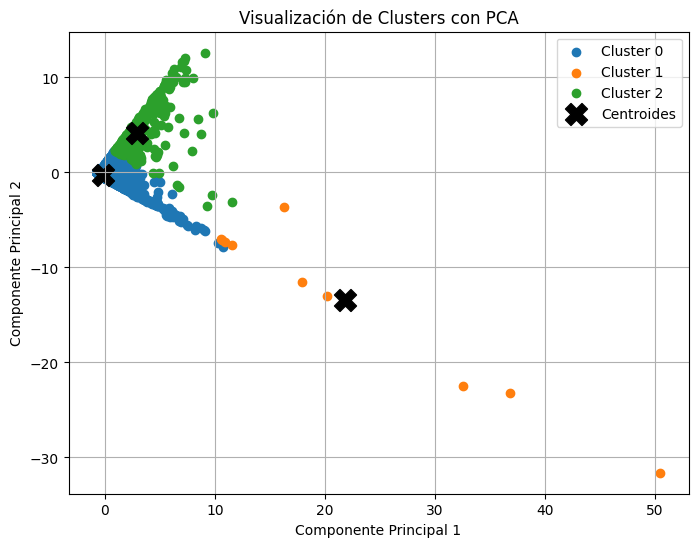

In [66]:
# 2. Entrenar KMeans con el número óptimo de clusters

kmeans = KMeans(n_clusters=optimal_k, random_state=42)
clusters = kmeans.fit_predict(df)

# 3. Calcular distancias a los centroides
distancias = cdist(df, kmeans.cluster_centers_, metric='euclidean')
print("Distancia del primer punto a cada centroide:")
print(distancias[0])

# Visualizar la matriz de distancias
dist_df = pd.DataFrame(distancias, columns=[f"Centroide {i}" for i in range(optimal_k)])
print(dist_df.head())

# 4. Visualización de clusters con PCA
pca = PCA(n_components=2)
X_pca = pca.fit_transform(df)

plt.figure(figsize=(8, 6))
for i in range(optimal_k):
    plt.scatter(X_pca[clusters == i, 0], X_pca[clusters == i, 1], label=f'Cluster {i}')

plt.scatter(pca.transform(kmeans.cluster_centers_)[:, 0],
            pca.transform(kmeans.cluster_centers_)[:, 1],
            s=250, c='black', marker='X', label='Centroides')
plt.title('Visualización de Clusters con PCA')
plt.xlabel('Componente Principal 1')
plt.ylabel('Componente Principal 2')
plt.legend()
plt.grid(True)
plt.show()

In [67]:
# Mostrar los valores de los centroides para cada variable
centroides = pd.DataFrame(kmeans.cluster_centers_, columns=df.columns)
print(centroides)

     amount  oldbalanceOrg  newbalanceOrig  oldbalanceDest  newbalanceDest  \
0 -0.007663      -0.207822       -0.207869       -0.037184       -0.032625   
1  6.299781       0.115591        0.115642       17.674776       17.823305   
2 -0.011341       3.478337        3.479120        0.230908        0.151260   

   type_CASH_IN  type_CASH_OUT    type_DEBIT  type_PAYMENT  type_TRANSFER  
0      0.177125   3.804607e-01  6.354249e-03  3.521313e-01       0.083929  
1      0.100000   4.000000e-01  0.000000e+00  0.000000e+00       0.500000  
2      0.997783   2.220446e-16 -2.602085e-18  2.220446e-16       0.002217  


In [68]:
# # Agrega la columna de cluster al DataFrame
# df['cluster'] = clusters

# # Calcula el monto promedio y otras estadísticas por cluster
# resumen = df.groupby('cluster').agg({
#     'amount': ['mean', 'min', 'max', 'count'],
#     'oldbalanceOrg': 'mean',
#     'newbalanceOrig': 'mean'
# })
# print(resumen)

Casos de prueba

Transacción de prueba 1 pertenece al cluster: 1
Transacción de prueba 2 pertenece al cluster: 1
Transacción de prueba 3 pertenece al cluster: 1


c:\Users\Cogito ergo sum\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\base.py:493: UserWarning: X does not have valid feature names, but KMeans was fitted with feature names
  warnings.warn(
c:\Users\Cogito ergo sum\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\base.py:493: UserWarning: X does not have valid feature names, but PCA was fitted with feature names
  warnings.warn(
c:\Users\Cogito ergo sum\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\base.py:493: UserWarning: X does not have valid feature names, but PCA was fitted with feature names
  warnings.warn(
c:\Users\Cogito ergo sum\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\base.py:493: UserWarning: X does not have valid feature names, but PCA was fitted with feature names
  warnings.warn(


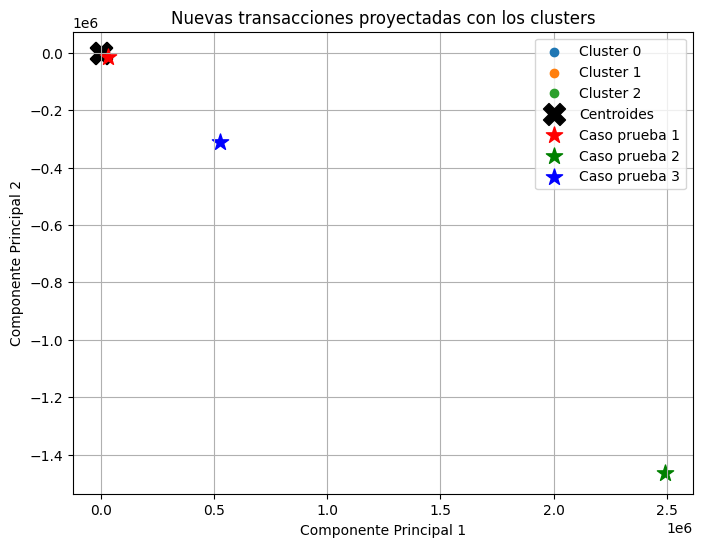

In [69]:
# Se ingresan: amount, oldbalanceOrg, newbalanceOrig, oldbalanceDest, newbalanceDest, type_CASH_IN, type_CASH_OUT, type_DEBIT, type_PAYMENT, type_TRANSFER

# Caso 1: (valores bajos-medios)
caso_1 = [10000, 5000, 0, 20000, 30000, 0, 0, 0, 1, 0]  # PAYMENT

# Caso 2: (valores muy altos)
caso_2 = [250000, 100000, 0, 2000000, 2250000, 0, 1, 0, 0, 0]  # CASH_OUT

# Caso 3: (valores intermedios)
caso_3 = [80000, 20000, 0, 400000, 480000, 0, 0, 0, 0, 1]  # TRANSFER

casos_prueba = np.array([caso_1, caso_2, caso_3])

# Predecir a qué cluster pertenece cada transacción
clusters_predichos = kmeans.predict(casos_prueba)
for i, cluster in enumerate(clusters_predichos):
    print(f"Transacción de prueba {i+1} pertenece al cluster: {cluster}")

# Proyectar las nuevas transacciones en el espacio PCA
casos_pca = pca.transform(casos_prueba)

# Graficar los clusters y las nuevas transacciones
plt.figure(figsize=(8, 6))
for i in range(optimal_k):
    plt.scatter(X_pca[clusters == i, 0], X_pca[clusters == i, 1], label=f'Cluster {i}')

plt.scatter(pca.transform(kmeans.cluster_centers_)[:, 0],
            pca.transform(kmeans.cluster_centers_)[:, 1],
            s=250, c='black', marker='X', label='Centroides')

colores = ['red', 'green', 'blue']
for i in range(3):
    plt.scatter(casos_pca[i, 0], casos_pca[i, 1], c=colores[i], s=150, marker='*', label=f'Caso prueba {i+1}')

plt.title('Nuevas transacciones proyectadas con los clusters')
plt.xlabel('Componente Principal 1')
plt.ylabel('Componente Principal 2')
plt.legend()
plt.grid(True)
plt.show()

##### Interpretación del caso de prueba 1: 

amount: 10000
→ El monto de la transacción es 10,000 unidades monetarias (valor bajo-medio).

oldbalanceOrg: 5000
→ El saldo anterior del origen (quien envía el dinero) es 5,000.

newbalanceOrig: 0
→ El saldo nuevo del origen después de la transacción es 0 (se quedó sin saldo).

oldbalanceDest: 20000
→ El saldo anterior del destino (quien recibe el dinero) es 20,000.

newbalanceDest: 30000
→ El saldo nuevo del destino después de la transacción es 30,000.

type_CASH_IN: 0
→ No es una transacción de tipo CASH_IN.

type_CASH_OUT: 0
→ No es una transacción de tipo CASH_OUT.

type_DEBIT: 0
→ No es una transacción de tipo DEBIT.

type_PAYMENT: 1
→ Es una transacción de tipo PAYMENT (pago).

type_TRANSFER: 0
→ No es una transacción de tipo TRANSFER.

#### DBSCAN

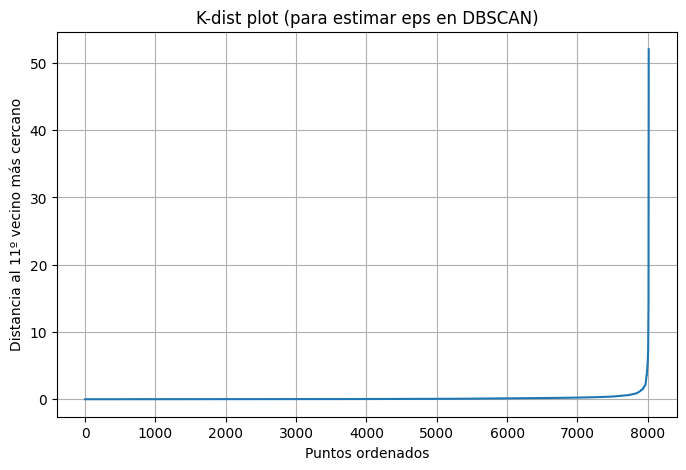

In [70]:
from sklearn.cluster import DBSCAN
from sklearn.neighbors import NearestNeighbors
from sklearn.decomposition import PCA
import numpy as np
import matplotlib.pyplot as plt

# Usamos los datos originales (sin escalar)
X = df.values

# 1. Gráfico K-dist para estimar eps
min_samples = 11  # MinPts = número de features + 1 = 10 + 1 = 11
neighbors = NearestNeighbors(n_neighbors=min_samples)
neighbors_fit = neighbors.fit(X)
distances, indices = neighbors_fit.kneighbors(X)
distances = np.sort(distances[:, min_samples-1])  # Tomamos la 11va distancia más cercana

plt.figure(figsize=(8, 5))
plt.plot(distances)
plt.title('K-dist plot (para estimar eps en DBSCAN)')
plt.xlabel('Puntos ordenados')
plt.ylabel(f'Distancia al {min_samples}º vecino más cercano')
plt.grid(True)
plt.show()


DBSCAN detectó 5 clusters


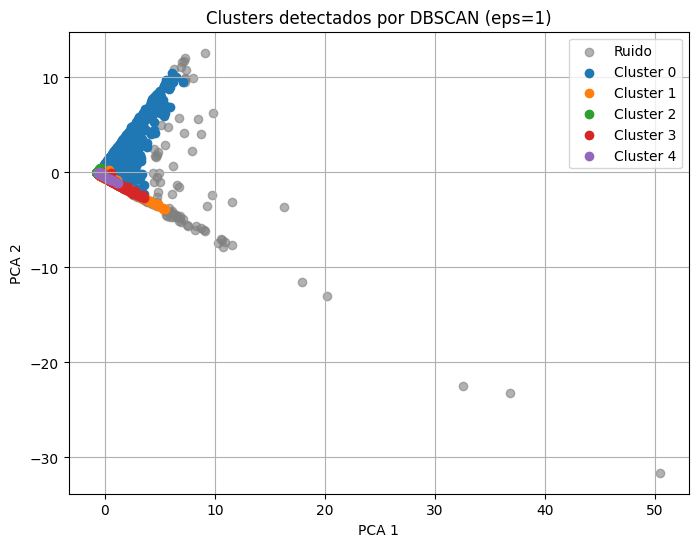

In [71]:

# 2. Se selecciona eps visualmente
eps_val =  1

# 3. Entrenamiento DBSCAN
dbscan = DBSCAN(eps=eps_val, min_samples=min_samples)
db_labels = dbscan.fit_predict(X)

# 4. Número de clusters detectados (sin contar ruido -1)
n_clusters = len(set(db_labels)) - (1 if -1 in db_labels else 0)
print(f"DBSCAN detectó {n_clusters} clusters")

# 5. Visualización con PCA
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X)

plt.figure(figsize=(8, 6))
for label in np.unique(db_labels):
    if label == -1:
        plt.scatter(X_pca[db_labels == label, 0], X_pca[db_labels == label, 1],
                    c='gray', label='Ruido', alpha=0.6)
    else:
        plt.scatter(X_pca[db_labels == label, 0], X_pca[db_labels == label, 1],
                    label=f'Cluster {label}')
plt.title(f'Clusters detectados por DBSCAN (eps={eps_val})')
plt.xlabel('PCA 1')
plt.ylabel('PCA 2')
plt.legend()
plt.grid(True)
plt.show()

Transacción de prueba 1 es considerada ruido (no pertenece a ningún cluster).
Transacción de prueba 2 es considerada ruido (no pertenece a ningún cluster).
Transacción de prueba 3 es considerada ruido (no pertenece a ningún cluster).


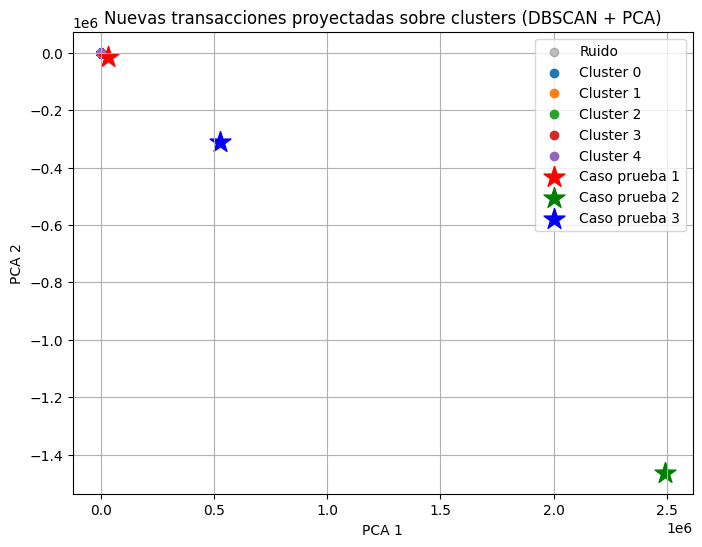

Silhouette score para DBSCAN: 0.5233081204873632


In [72]:

# 6. Casos de prueba (3 transacciones nuevas)
casos_prueba = np.array([
    [10000, 5000, 0, 20000, 30000, 0, 0, 0, 1, 0],      # Caso 1: PAYMENT, valores bajos-medios
    [250000, 100000, 0, 2000000, 2250000, 0, 1, 0, 0, 0], # Caso 2: CASH_OUT, valores muy altos
    [80000, 20000, 0, 400000, 480000, 0, 0, 0, 0, 1]      # Caso 3: TRANSFER, valores intermedios
])

# Predecir a qué cluster (o ruido) pertenece cada transacción de prueba
X_ext = np.vstack([X, casos_prueba])
db_labels_ext = dbscan.fit_predict(X_ext)
casos_predichos = db_labels_ext[-3:]

for i, cluster in enumerate(casos_predichos):
    if cluster == -1:
        print(f"Transacción de prueba {i+1} es considerada ruido (no pertenece a ningún cluster).")
    else:
        print(f"Transacción de prueba {i+1} pertenecería al Cluster {cluster}")

# Proyectar las nuevas transacciones en el espacio PCA
casos_pca = pca.transform(casos_prueba)

plt.figure(figsize=(8, 6))
for label in np.unique(db_labels):
    if label == -1:
        plt.scatter(X_pca[db_labels == label, 0], X_pca[db_labels == label, 1],
                    c='gray', label='Ruido', alpha=0.5)
    else:
        plt.scatter(X_pca[db_labels == label, 0], X_pca[db_labels == label, 1],
                    label=f'Cluster {label}')

colores = ['red', 'green', 'blue']
for i in range(3):
    plt.scatter(casos_pca[i, 0], casos_pca[i, 1], c=colores[i], s=250, marker='*', label=f'Caso prueba {i+1}')

plt.title('Nuevas transacciones proyectadas sobre clusters (DBSCAN + PCA)')
plt.xlabel('PCA 1')
plt.ylabel('PCA 2')
plt.legend()
plt.grid(True)
plt.show()

# 7. Silhouette score para DBSCAN
from sklearn.metrics import silhouette_score
if len(set(db_labels)) - (1 if -1 in db_labels else 0) > 1:
    mask = db_labels != -1
    sil_score = silhouette_score(X[mask], db_labels[mask])
    print(f"Silhouette score para DBSCAN: {sil_score}")
else:
    print("No se puede calcular silhouette score: menos de 2 clusters detectados.")

### Caso 8: CC(SI), ED(SI), Outliers (SI), Balanceo(SI)


#### K-MEANS

Determinamos el número óptimo de clusters con el método del codo y silhouette

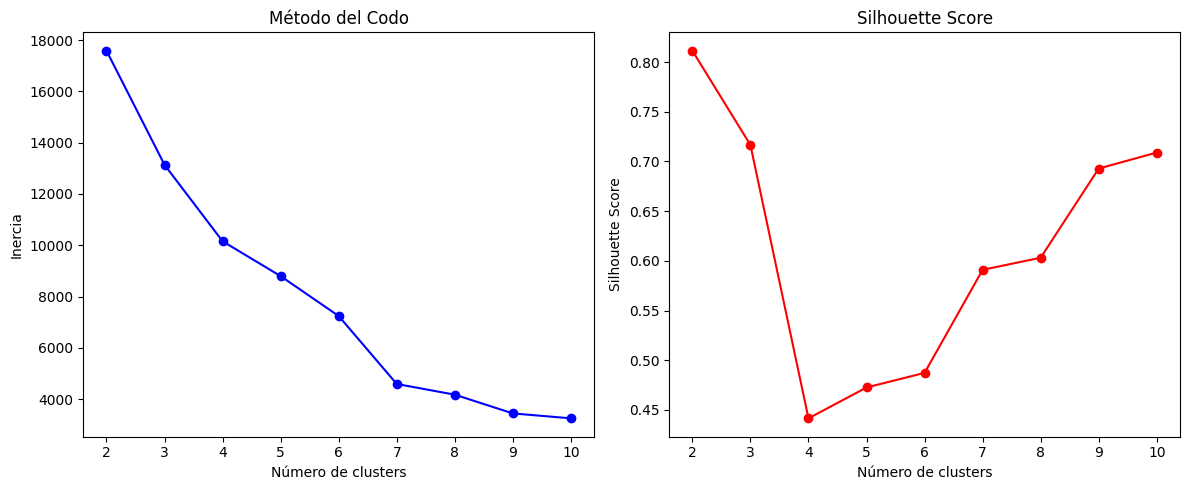

In [73]:
# 1. Cargamos el dataset caso 1
df = pd.read_csv('df_CC_SI_ED_Balanceado_Con_Outliers_Sin_Variable_Objetivo.csv')

# 2 K-Means: Encontrar el número óptimo de clusters
inertia = []
silhouette = []
K = range(2, 11)

for k in K:
    kmeans = KMeans(n_clusters=k, random_state=42)
    labels = kmeans.fit_predict(df)
    inertia.append(kmeans.inertia_)
    silhouette.append(silhouette_score(df, labels))

# Graficar la curva del codo
plt.figure(figsize=(12,5))
plt.subplot(1,2,1)
plt.plot(K, inertia, 'bo-')
plt.xlabel('Número de clusters')
plt.ylabel('Inercia')
plt.title('Método del Codo')

# Graficar el silhouette score
plt.subplot(1,2,2)
plt.plot(K, silhouette, 'ro-')
plt.xlabel('Número de clusters')
plt.ylabel('Silhouette Score')
plt.title('Silhouette Score')
plt.tight_layout()
plt.show()

In [74]:
print("Inercia para cada K:", inertia)
print("Silhouette score para cada K:", silhouette)

# para k=3
print(inertia[1])  # Inercia para k=3
print(silhouette[1])  # Silhouette score para k=3

Inercia para cada K: [17583.233104165094, 13132.961149525725, 10154.537247417687, 8796.568377844262, 7240.957526544016, 4592.432739693992, 4175.233658510783, 3444.774862067835, 3252.960620521345]
Silhouette score para cada K: [np.float64(0.8113760622500386), np.float64(0.7165691870936033), np.float64(0.44156210534692675), np.float64(0.47261833615034055), np.float64(0.4872973468385301), np.float64(0.590970089769494), np.float64(0.6031422583801119), np.float64(0.6928800230384398), np.float64(0.708932210050008)]
13132.961149525725
0.7165691870936033


##### Justificación del valor de K

El valor óptimo de k es 3, ya que en el método del codo se observa un quiebre claro en ese punto, lo que indica que aumentar el número de clústers después de 3 reduce la inercia de forma menos significativa. Además, el Silhouette Score alcanza su valor máximo en k = 3, lo que indica una excelente cohesión y separación entre clústers,

In [75]:
# el mejor K 
optimal_k = 3

Distancia del primer punto a cada centroide:
[1.24284932 8.56673981 6.62926327]
   Centroide 0  Centroide 1  Centroide 2
0     1.242849     8.566740     6.629263
1     5.923370    14.797386     0.868828
2     6.206863    15.066939     1.251781
3     5.874161    14.853571     0.774894
4     6.125230    14.997064     0.941306


c:\Users\Cogito ergo sum\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\base.py:493: UserWarning: X does not have valid feature names, but PCA was fitted with feature names
  warnings.warn(
c:\Users\Cogito ergo sum\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\base.py:493: UserWarning: X does not have valid feature names, but PCA was fitted with feature names
  warnings.warn(


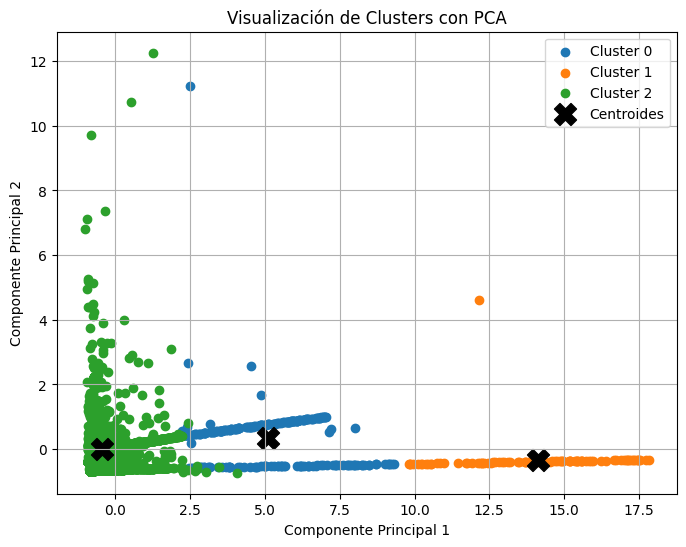

In [76]:
# 2. Entrenar KMeans con el número óptimo de clusters

kmeans = KMeans(n_clusters=optimal_k, random_state=42)
clusters = kmeans.fit_predict(df)

# 3. Calcular distancias a los centroides
distancias = cdist(df, kmeans.cluster_centers_, metric='euclidean')
print("Distancia del primer punto a cada centroide:")
print(distancias[0])

# Visualizar la matriz de distancias
dist_df = pd.DataFrame(distancias, columns=[f"Centroide {i}" for i in range(optimal_k)])
print(dist_df.head())

# 4. Visualización de clusters con PCA
pca = PCA(n_components=2)
X_pca = pca.fit_transform(df)

plt.figure(figsize=(8, 6))
for i in range(optimal_k):
    plt.scatter(X_pca[clusters == i, 0], X_pca[clusters == i, 1], label=f'Cluster {i}')

plt.scatter(pca.transform(kmeans.cluster_centers_)[:, 0],
            pca.transform(kmeans.cluster_centers_)[:, 1],
            s=250, c='black', marker='X', label='Centroides')
plt.title('Visualización de Clusters con PCA')
plt.xlabel('Componente Principal 1')
plt.ylabel('Componente Principal 2')
plt.legend()
plt.grid(True)
plt.show()

In [77]:
# Mostrar los valores de los centroides para cada variable
centroides = pd.DataFrame(kmeans.cluster_centers_, columns=df.columns)
print(centroides)

      amount  oldbalanceOrg  newbalanceOrig  oldbalanceDest  newbalanceDest  \
0   5.574421       1.149351       -0.000100       -0.237570        0.315007   
1  13.520198       5.025141        2.220309       -0.279064       -0.274497   
2   0.127018      -0.156546       -0.237798       -0.078729       -0.062836   

   type_CASH_IN  type_CASH_OUT    type_DEBIT  type_PAYMENT  type_TRANSFER  
0  1.387779e-17   5.966387e-01 -1.301043e-18 -5.551115e-17       0.403361  
1 -1.387779e-17   1.110223e-16 -4.336809e-19  0.000000e+00       1.000000  
2  4.567901e-02   4.708995e-01  2.116402e-03  7.354497e-02       0.407760  


In [78]:
# # Agrega la columna de cluster al DataFrame
# df['cluster'] = clusters

# # Calcula el monto promedio y otras estadísticas por cluster
# resumen = df.groupby('cluster').agg({
#     'amount': ['mean', 'min', 'max', 'count'],
#     'oldbalanceOrg': 'mean',
#     'newbalanceOrig': 'mean'
# })
# print(resumen)

Casos de prueba

c:\Users\Cogito ergo sum\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\base.py:493: UserWarning: X does not have valid feature names, but KMeans was fitted with feature names
  warnings.warn(
c:\Users\Cogito ergo sum\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\base.py:493: UserWarning: X does not have valid feature names, but PCA was fitted with feature names
  warnings.warn(
c:\Users\Cogito ergo sum\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\base.py:493: UserWarning: X does not have valid feature names, but PCA was fitted with feature names
  warnings.warn(
c:\Users\Cogito ergo sum\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\base.py:493: UserWarning: X does not have valid feature names, but PCA was fitted with feature names
  warnings.warn(


Transacción de prueba 1 pertenece al cluster: 1
Transacción de prueba 2 pertenece al cluster: 1
Transacción de prueba 3 pertenece al cluster: 1


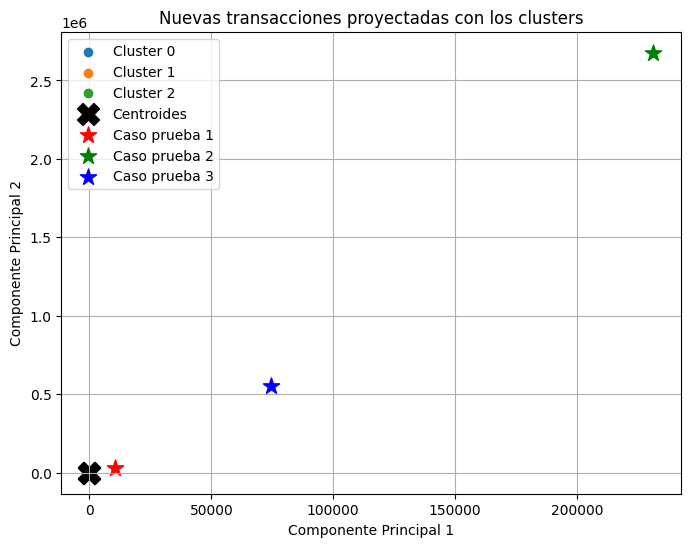

In [79]:
# Se ingresan: amount, oldbalanceOrg, newbalanceOrig, oldbalanceDest, newbalanceDest, type_CASH_IN, type_CASH_OUT, type_DEBIT, type_PAYMENT, type_TRANSFER

# Caso 1: (valores bajos-medios)
caso_1 = [10000, 5000, 0, 20000, 30000, 0, 0, 0, 1, 0]  # PAYMENT

# Caso 2: (valores muy altos)
caso_2 = [250000, 100000, 0, 2000000, 2250000, 0, 1, 0, 0, 0]  # CASH_OUT

# Caso 3: (valores intermedios)
caso_3 = [80000, 20000, 0, 400000, 480000, 0, 0, 0, 0, 1]  # TRANSFER

casos_prueba = np.array([caso_1, caso_2, caso_3])

# Predecir a qué cluster pertenece cada transacción
clusters_predichos = kmeans.predict(casos_prueba)
for i, cluster in enumerate(clusters_predichos):
    print(f"Transacción de prueba {i+1} pertenece al cluster: {cluster}")

# Proyectar las nuevas transacciones en el espacio PCA
casos_pca = pca.transform(casos_prueba)

# Graficar los clusters y las nuevas transacciones
plt.figure(figsize=(8, 6))
for i in range(optimal_k):
    plt.scatter(X_pca[clusters == i, 0], X_pca[clusters == i, 1], label=f'Cluster {i}')

plt.scatter(pca.transform(kmeans.cluster_centers_)[:, 0],
            pca.transform(kmeans.cluster_centers_)[:, 1],
            s=250, c='black', marker='X', label='Centroides')

colores = ['red', 'green', 'blue']
for i in range(3):
    plt.scatter(casos_pca[i, 0], casos_pca[i, 1], c=colores[i], s=150, marker='*', label=f'Caso prueba {i+1}')

plt.title('Nuevas transacciones proyectadas con los clusters')
plt.xlabel('Componente Principal 1')
plt.ylabel('Componente Principal 2')
plt.legend()
plt.grid(True)
plt.show()

##### Interpretación del caso de prueba 1: 

amount: 10000
→ El monto de la transacción es 10,000 unidades monetarias (valor bajo-medio).

oldbalanceOrg: 5000
→ El saldo anterior del origen (quien envía el dinero) es 5,000.

newbalanceOrig: 0
→ El saldo nuevo del origen después de la transacción es 0 (se quedó sin saldo).

oldbalanceDest: 20000
→ El saldo anterior del destino (quien recibe el dinero) es 20,000.

newbalanceDest: 30000
→ El saldo nuevo del destino después de la transacción es 30,000.

type_CASH_IN: 0
→ No es una transacción de tipo CASH_IN.

type_CASH_OUT: 0
→ No es una transacción de tipo CASH_OUT.

type_DEBIT: 0
→ No es una transacción de tipo DEBIT.

type_PAYMENT: 1
→ Es una transacción de tipo PAYMENT (pago).

type_TRANSFER: 0
→ No es una transacción de tipo TRANSFER.

#### DBSCAN

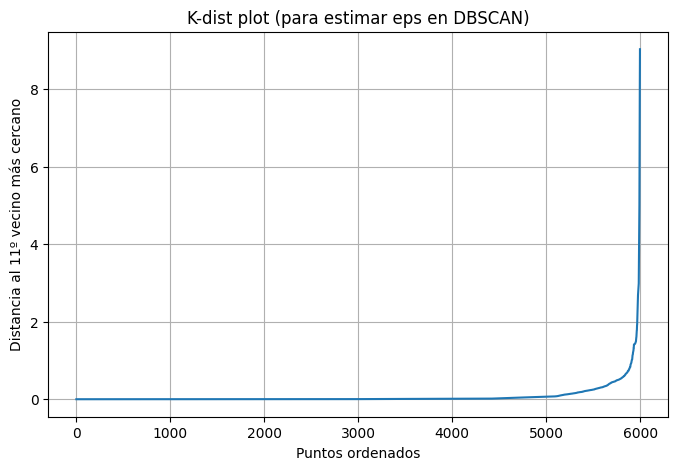

In [80]:
from sklearn.cluster import DBSCAN
from sklearn.neighbors import NearestNeighbors
from sklearn.decomposition import PCA
import numpy as np
import matplotlib.pyplot as plt

# Usamos los datos originales (sin escalar)
X = df.values

# 1. Gráfico K-dist para estimar eps
min_samples = 11  # MinPts = número de features + 1 = 10 + 1 = 11
neighbors = NearestNeighbors(n_neighbors=min_samples)
neighbors_fit = neighbors.fit(X)
distances, indices = neighbors_fit.kneighbors(X)
distances = np.sort(distances[:, min_samples-1])  # Tomamos la 11va distancia más cercana

plt.figure(figsize=(8, 5))
plt.plot(distances)
plt.title('K-dist plot (para estimar eps en DBSCAN)')
plt.xlabel('Puntos ordenados')
plt.ylabel(f'Distancia al {min_samples}º vecino más cercano')
plt.grid(True)
plt.show()


DBSCAN detectó 4 clusters


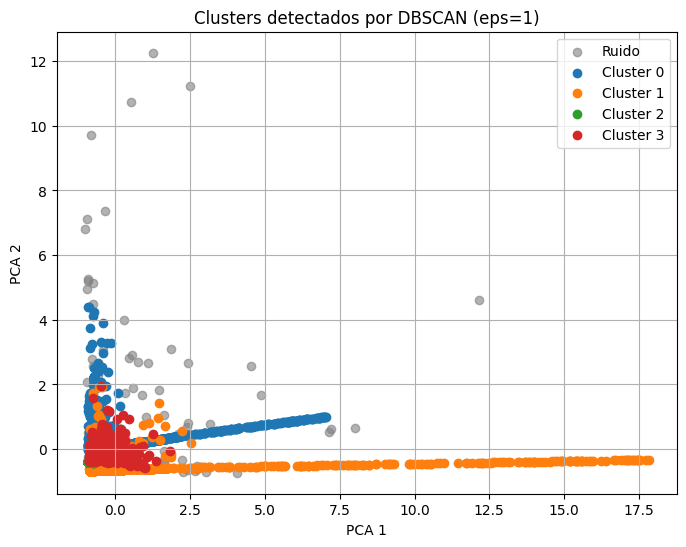

In [81]:

# 2. Se selecciona eps visualmente
eps_val =  1

# 3. Entrenamiento DBSCAN
dbscan = DBSCAN(eps=eps_val, min_samples=min_samples)
db_labels = dbscan.fit_predict(X)

# 4. Número de clusters detectados (sin contar ruido -1)
n_clusters = len(set(db_labels)) - (1 if -1 in db_labels else 0)
print(f"DBSCAN detectó {n_clusters} clusters")

# 5. Visualización con PCA
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X)

plt.figure(figsize=(8, 6))
for label in np.unique(db_labels):
    if label == -1:
        plt.scatter(X_pca[db_labels == label, 0], X_pca[db_labels == label, 1],
                    c='gray', label='Ruido', alpha=0.6)
    else:
        plt.scatter(X_pca[db_labels == label, 0], X_pca[db_labels == label, 1],
                    label=f'Cluster {label}')
plt.title(f'Clusters detectados por DBSCAN (eps={eps_val})')
plt.xlabel('PCA 1')
plt.ylabel('PCA 2')
plt.legend()
plt.grid(True)
plt.show()

Transacción de prueba 1 es considerada ruido (no pertenece a ningún cluster).
Transacción de prueba 2 es considerada ruido (no pertenece a ningún cluster).
Transacción de prueba 3 es considerada ruido (no pertenece a ningún cluster).


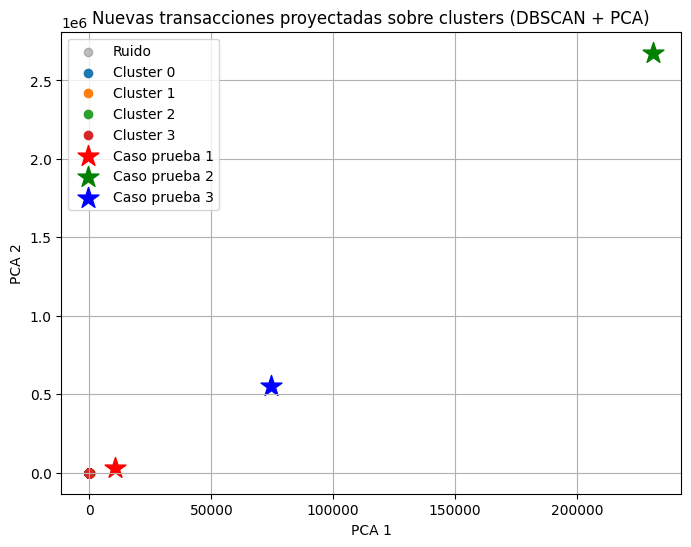

Silhouette score para DBSCAN: 0.27473249955129386


In [82]:

# 6. Casos de prueba (3 transacciones nuevas)
casos_prueba = np.array([
    [10000, 5000, 0, 20000, 30000, 0, 0, 0, 1, 0],      # Caso 1: PAYMENT, valores bajos-medios
    [250000, 100000, 0, 2000000, 2250000, 0, 1, 0, 0, 0], # Caso 2: CASH_OUT, valores muy altos
    [80000, 20000, 0, 400000, 480000, 0, 0, 0, 0, 1]      # Caso 3: TRANSFER, valores intermedios
])

# Predecir a qué cluster (o ruido) pertenece cada transacción de prueba
X_ext = np.vstack([X, casos_prueba])
db_labels_ext = dbscan.fit_predict(X_ext)
casos_predichos = db_labels_ext[-3:]

for i, cluster in enumerate(casos_predichos):
    if cluster == -1:
        print(f"Transacción de prueba {i+1} es considerada ruido (no pertenece a ningún cluster).")
    else:
        print(f"Transacción de prueba {i+1} pertenecería al Cluster {cluster}")

# Proyectar las nuevas transacciones en el espacio PCA
casos_pca = pca.transform(casos_prueba)

plt.figure(figsize=(8, 6))
for label in np.unique(db_labels):
    if label == -1:
        plt.scatter(X_pca[db_labels == label, 0], X_pca[db_labels == label, 1],
                    c='gray', label='Ruido', alpha=0.5)
    else:
        plt.scatter(X_pca[db_labels == label, 0], X_pca[db_labels == label, 1],
                    label=f'Cluster {label}')

colores = ['red', 'green', 'blue']
for i in range(3):
    plt.scatter(casos_pca[i, 0], casos_pca[i, 1], c=colores[i], s=250, marker='*', label=f'Caso prueba {i+1}')

plt.title('Nuevas transacciones proyectadas sobre clusters (DBSCAN + PCA)')
plt.xlabel('PCA 1')
plt.ylabel('PCA 2')
plt.legend()
plt.grid(True)
plt.show()

# 7. Silhouette score para DBSCAN
from sklearn.metrics import silhouette_score
if len(set(db_labels)) - (1 if -1 in db_labels else 0) > 1:
    mask = db_labels != -1
    sil_score = silhouette_score(X[mask], db_labels[mask])
    print(f"Silhouette score para DBSCAN: {sil_score}")
else:
    print("No se puede calcular silhouette score: menos de 2 clusters detectados.")

## Resultado en grafica de barras


C:\Users\Cogito ergo sum\AppData\Local\Temp\ipykernel_2908\1793071248.py:17: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axes[0].set_xticklabels(labels, rotation=45)
C:\Users\Cogito ergo sum\AppData\Local\Temp\ipykernel_2908\1793071248.py:24: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axes[1].set_xticklabels(labels, rotation=45)


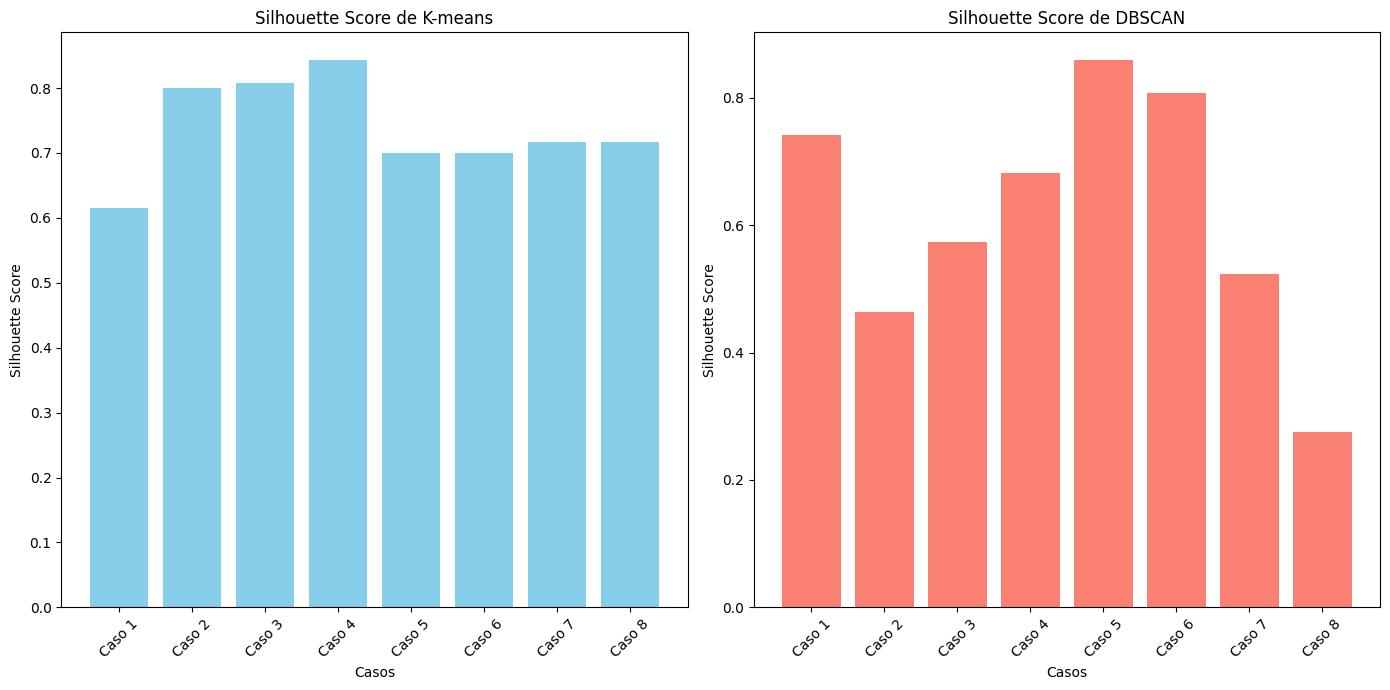

In [83]:
import matplotlib.pyplot as plt
import numpy as np

# Datos para el gráfico
labels = ['Caso 1', 'Caso 2', 'Caso 3', 'Caso 4', 'Caso 5', 'Caso 6', 'Caso 7', 'Caso 8']
kmeans_scores = [0.6155136875, 0.8001333312, 0.8075802827, 0.8436411613, 0.6998634333, 0.6998634333, 0.7165691871, 0.7165691871]
dbscan_scores = [0.74179099864, 0.4637318042, 0.573717969, 0.6819174505, 0.8596316074, 0.8068627602, 0.5233081205, 0.2747324996]

# Crear las gráficas de barras
fig, axes = plt.subplots(1, 2, figsize=(14, 7))

# K-means
axes[0].bar(labels, kmeans_scores, color='skyblue')
axes[0].set_title('Silhouette Score de K-means')
axes[0].set_xlabel('Casos')
axes[0].set_ylabel('Silhouette Score')
axes[0].set_xticklabels(labels, rotation=45)

# DBSCAN
axes[1].bar(labels, dbscan_scores, color='salmon')
axes[1].set_title('Silhouette Score de DBSCAN')
axes[1].set_xlabel('Casos')
axes[1].set_ylabel('Silhouette Score')
axes[1].set_xticklabels(labels, rotation=45)

# Ajustar el espaciado entre las gráficas y mostrar
plt.tight_layout()
plt.show()
